<a href="https://colab.research.google.com/github/dousiyuzu1207/-dog-human-coordination/blob/main/M2BD_CC_practical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/adrdufour/M2BD-transcriptomics/blob/main/M2BD_CC_practical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transcriptomic analyses in neurodevelopment — practical session

**M2 Brain Disorders · UE2 Genetics and Neurodevelopment**  ·  Adrien Dufour, Inserm

> **Save your own copy first:** *File → Save a copy in Drive*. Otherwise nothing you type here
> survives the end of the session.

Three blocks, six numbered figures. Your graded worksheet asks about each figure **by its number**,
so when a cell prints `Figure 3`, that is the figure the worksheet means.

| Block | Time | You produce | Worksheet |
|---|---|---|---|
| **A** — bulk RNA-seq | 15 min | Figure 1, Figure 2 | Q1, Q2 |
| **B** — single-cell | 25 min | Figure 3, Figure 4 | Q3, Q4 |
| **C** — spatial + integration | 20 min | Figure 5, Figure 6 | Q5, Q6, Q7 |

**Two rules for today.** You are marked on how you *read* your own figures, not on whether your code
ran — so if a cell fails, move on and answer from the figure handout. And answer the worksheet **as you
go**: the last ten minutes are not enough.

---
### Run this first (≈ 2 min)

In [2]:
# SETUP — run this cell once. About two minutes, most of it the pip install.

import os, sys, subprocess, textwrap, urllib.request, pathlib

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    subprocess.run("pip install -q scanpy leidenalg igraph", shell=True, check=False)

# The three datasets live in the course repository. The two simulated ones
# (bulk, single-cell) are rebuilt locally from a fixed seed (~5 s) if GitHub is
# unreachable from this room. The Visium dataset is real data and can only be
# downloaded: without it, Block C2 is answered from the figure handout.
REPO = "adrdufour/M2BD-transcriptomics"
DATA_URL_BASE = os.environ.get(
    "M2BD_DATA_URL", f"https://raw.githubusercontent.com/{REPO}/main/data")
DATA_DIR = pathlib.Path("data"); DATA_DIR.mkdir(exist_ok=True)
SIMULATED = ["bulk_cortex.h5ad", "fetal_cortex_sc.h5ad"]
VISIUM = "rat_visium_SE.h5ad"
FILES = SIMULATED + [VISIUM]

# --- the two helper modules, written to disk so you can open and read them ---
pathlib.Path("cc_datasets.py").write_text('"""\nDeterministic generator for the two simulated CC datasets.\n\n    bulk_cortex.h5ad      developmental bulk cortex + a case/control contrast\n    fetal_cortex_sc.h5ad  mid-gestation cortex nuclei, raw counts, no QC applied\n\nThe third dataset, rat_visium_SE.h5ad, is real data and is not generated here:\nsee prepare_visium.py.\n\nBoth are built from ONE shared cell-type expression profile matrix e(g, k),\nso that:\n  * the single-cell object is a valid reference for deconvolving the bulk object\n  * the bulk signal really is  sum_k p_k * e(g, k)  (the "bulk equation", Q5)\n  * cases differ from controls BOTH in composition (fewer neurons, more glia and\n    microglia) AND in regulation (excitatory neurons down-regulate the synaptic\n    module) -- so the correct answer to Q5a is "both", with evidence.\n\nSeeded; running it twice gives byte-identical objects.\n\nUsage:  python cc_datasets.py OUTDIR\n"""\n\nimport sys\nimport numpy as np\nimport pandas as pd\nimport anndata as ad\nfrom scipy import sparse\n\nSEED = 20260904\n\n# --------------------------------------------------------------------------\n# 1.  Genes\n# --------------------------------------------------------------------------\n\nMARKERS = {\n    # progenitors\n    "RG":         ["VIM", "SOX2", "PAX6", "HES1", "HES5", "SLC1A3", "NES", "GLI3", "TTYH1"],\n    "oRG":        ["HOPX", "PTPRZ1", "FAM107A", "TNC", "MOXD1", "LIFR", "SLC1A3", "VIM"],\n    "IPC":        ["EOMES", "PPP1R17", "NEUROG1", "NEUROG2", "PENK", "ELAVL4"],\n    # neurons\n    "ExN_deep":   ["BCL11B", "FEZF2", "TBR1", "CRYM", "SOX5", "NEUROD2", "NEUROD6", "SYN1", "SNAP25"],\n    "ExN_upper":  ["SATB2", "CUX2", "RORB", "POU3F2", "NEUROD2", "NEUROD6", "SYN1", "SNAP25"],\n    "IN_MGE":     ["DLX1", "DLX2", "GAD1", "GAD2", "LHX6", "SST", "SNAP25"],\n    "IN_CGE":     ["DLX1", "DLX2", "GAD1", "GAD2", "SP8", "NR2F2", "SNAP25"],\n    "CR":         ["RELN", "TP73", "LHX1", "TBR1"],\n    # glia\n    "Astro":      ["AQP4", "ALDH1L1", "GFAP", "S100B", "SLC1A3", "GJA1", "SPARCL1"],\n    "OPC":        ["OLIG1", "OLIG2", "PDGFRA", "CSPG4", "SOX10"],\n    "Micro":      ["AIF1", "C1QA", "C1QB", "C1QC", "P2RY12", "CX3CR1", "TYROBP", "TREM2", "CSF1R"],\n    "Endo":       ["CLDN5", "PECAM1", "FLT1", "RGS5"],\n}\n\nCELL_TYPES = list(MARKERS)\n\n# the two modules the volcano plot is built around\nSYNAPTIC = [\n    "SYN1", "SYN2", "SNAP25", "SYT1", "SYP", "DLG4", "GRIN1", "GRIN2B", "GRIA1",\n    "GRIA2", "NRXN1", "NRXN3", "NLGN1", "NLGN3", "STXBP1", "RAB3A", "CAMK2A",\n    "CAMK2B", "GABRB3", "GABRA1", "SCN2A", "CACNA1E", "KCNQ2", "SHANK2",\n    "SHANK3", "DLGAP1", "HOMER1", "PCLO", "BSN", "CPLX1", "CPLX2", "VAMP2",\n    "STX1A", "SV2A", "NEFL", "NEFM", "MAP2", "TUBB3", "RBFOX3", "ATP2B2",\n]\nIMMUNE_GLIAL = [\n    "C1QA", "C1QB", "C1QC", "AIF1", "TYROBP", "TREM2", "CSF1R", "CD68",\n    "P2RY12", "CX3CR1", "ITGAM", "PTPRC", "IFITM2", "IFITM3", "B2M", "HLA-A",\n    "HLA-B", "HLA-DRA", "CD74", "GFAP", "AQP4", "S100B", "VIM", "CHI3L1",\n    "SERPINA3", "CRYAB", "MT2A", "MT1X", "SOX9", "ID3", "NFKBIA", "TNFRSF1A",\n    "IL33", "CCL3", "CCL4", "SPP1", "APOE", "CLU", "A2M", "TIMP1",\n]\nMT_GENES = ["MT-ND1", "MT-ND2", "MT-CO1", "MT-CO2", "MT-ATP6", "MT-CO3",\n            "MT-ND3", "MT-ND4", "MT-ND5", "MT-CYB", "MT-ND4L", "MT-ATP8", "MT-ND6"]\n\nN_FILLER = 2600\nFILLER = [f"AC{i:06d}.1" if i % 3 == 0 else f"GENE{i:05d}" for i in range(N_FILLER)]\n\n# A co-expression module is hundreds of genes, not the forty that have famous\n# names. The named genes above are the ones the volcano plot labels; these are\n# the full modules that actually move together.\n_perm = np.random.default_rng(777).permutation(N_FILLER)\nSYNAPTIC_MODULE = SYNAPTIC + [FILLER[i] for i in _perm[:230]]\nIMMUNE_MODULE = IMMUNE_GLIAL + [FILLER[i] for i in _perm[230:460]]\n\n\ndef gene_universe():\n    named = []\n    for v in MARKERS.values():\n        named += v\n    named += SYNAPTIC + IMMUNE_GLIAL + MT_GENES\n    named = sorted(set(named))\n    return named + FILLER\n\n\n# --------------------------------------------------------------------------\n# 2.  Shared cell-type expression profiles  e(g, k)\n# --------------------------------------------------------------------------\n\ndef build_profiles(genes, rng):\n    """Mean expression per gene per cell type, on a linear (CPM-like) scale."""\n    G, K = len(genes), len(CELL_TYPES)\n    idx = {g: i for i, g in enumerate(genes)}\n\n    # housekeeping baseline shared by all cell types: log-normal\n    base = np.exp(rng.normal(1.2, 1.1, size=G))\n    E = np.tile(base[:, None], (1, K))\n\n    # cell-type-specific noise so that types are not identical\n    # Most genes are somewhat cell-type-preferential, not only the markers.\n    # This is what makes a shift in composition move hundreds of genes in the\n    # bulk contrast -- the whole point of Q5.\n    E *= np.exp(rng.normal(0, 0.80, size=(G, K)))\n\n    for k, ct in enumerate(CELL_TYPES):\n        for g in MARKERS[ct]:\n            E[idx[g], k] *= 45.0\n\n    # module-level structure\n    neuronal = [CELL_TYPES.index(c) for c in ["ExN_deep", "ExN_upper", "IN_MGE", "IN_CGE", "CR"]]\n    glial = [CELL_TYPES.index(c) for c in ["Astro", "Micro", "OPC"]]\n    for g in SYNAPTIC_MODULE:\n        E[idx[g], :] *= 0.35\n        E[idx[g], neuronal] *= 22.0\n    for g in IMMUNE_MODULE:\n        E[idx[g], :] *= 0.5\n        E[idx[g], glial] *= 14.0\n    # microglia carry the immune half of the module hardest\n    mic = CELL_TYPES.index("Micro")\n    for g in IMMUNE_GLIAL[:20]:\n        E[idx[g], mic] *= 4.0\n\n    # Mitochondrial transcripts: set the MT fraction per cell type explicitly,\n    # genuinely higher in mature neurons because they are metabolically\n    # demanding. This is what makes a blanket 5% MT cut-off delete neurons (Q3b).\n    mt_i = np.array([idx[g] for g in MT_GENES])\n    target = np.full(K, 0.030)\n    for c in ["ExN_deep", "ExN_upper", "IN_MGE", "IN_CGE", "CR"]:\n        target[CELL_TYPES.index(c)] = 0.075\n    target[CELL_TYPES.index("Micro")] = 0.018\n    target[CELL_TYPES.index("Endo")] = 0.022\n    for k in range(K):\n        other = E[:, k].sum() - E[mt_i, k].sum()\n        E[mt_i, k] *= (target[k] * other) / ((1 - target[k]) * E[mt_i, k].sum())\n\n    return E, idx\n\n\n# --------------------------------------------------------------------------\n# 3.  Composition as a function of developmental age\n# --------------------------------------------------------------------------\n\ndef proportions(age_pcw, rng, case=False):\n    """Cell-type proportions at a given post-conceptional week."""\n    t = np.clip((age_pcw - 8) / 32.0, 0, 1)          # 0 at 8 pcw, 1 at 40 pcw\n    p = {\n        "RG":        0.26 * (1 - t) ** 1.4 + 0.02,\n        "oRG":       0.13 * np.exp(-((t - 0.35) ** 2) / 0.06) + 0.01,\n        "IPC":       0.14 * (1 - t) ** 1.1 + 0.01,\n        "ExN_deep":  0.06 + 0.16 * t,\n        "ExN_upper": 0.02 + 0.28 * t ** 1.3,\n        "IN_MGE":    0.03 + 0.05 * t,\n        "IN_CGE":    0.02 + 0.04 * t,\n        "CR":        0.02 * (1 - t) + 0.002,\n        "Astro":     0.01 + 0.10 * t ** 1.8,\n        "OPC":       0.005 + 0.05 * t ** 2.0,\n        "Micro":     0.02 + 0.04 * t,\n        "Endo":      0.02 + 0.01 * t,\n    }\n    v = np.array([p[c] for c in CELL_TYPES], float)\n\n    if case:\n        # composition difference in cases: fewer excitatory neurons,\n        # more microglia and astrocytes.  This is HALF of the Q2 signal.\n        v[CELL_TYPES.index("ExN_upper")] *= 0.74\n        v[CELL_TYPES.index("ExN_deep")] *= 0.86\n        v[CELL_TYPES.index("Micro")] *= 1.70\n        v[CELL_TYPES.index("Astro")] *= 1.35\n\n    v *= np.exp(rng.normal(0, 0.12, size=v.size))     # donor-to-donor variability\n    return v / v.sum()\n\n\n# --------------------------------------------------------------------------\n# 4.  Bulk\n# --------------------------------------------------------------------------\n\ndef make_bulk(genes, E, idx, rng):\n    rows = []\n    # (a) developmental series, controls only, 8 -> 40 pcw\n    ages = np.round(np.linspace(8, 39, 24) + rng.normal(0, 0.4, 24), 1)\n    for i, a in enumerate(ages):\n        rows.append(dict(sample_id=f"DEV{i+1:02d}", cohort="development",\n                         diagnosis="control", age_pcw=float(a)))\n    # (b) case/control contrast, age-matched, late fetal (20 vs 20)\n    for i in range(40):\n        a = float(np.round(rng.uniform(30, 38), 1))\n        rows.append(dict(sample_id=f"CC{i+1:02d}", cohort="contrast",\n                         diagnosis="case" if i % 2 == 0 else "control", age_pcw=a))\n\n    obs = pd.DataFrame(rows).set_index("sample_id")\n    n = obs.shape[0]\n    obs["region"] = rng.choice(["PFC", "V1", "TC"], n, p=[0.5, 0.25, 0.25])\n    obs["sex"] = rng.choice(["M", "F"], n)\n    obs["RIN"] = np.round(rng.uniform(5.8, 9.2, n), 1)\n    obs["PMI_h"] = np.round(rng.uniform(4, 28, n), 1)\n    # batch is balanced across diagnosis on purpose: the honest teaching case\n    obs["batch"] = np.where(np.arange(n) % 3 == 0, "B1", np.where(np.arange(n) % 3 == 1, "B2", "B3"))\n\n    G = len(genes)\n    P = np.zeros((n, len(CELL_TYPES)))\n    mu = np.zeros((n, G))\n\n    # regulatory effect: in cases, excitatory neurons themselves down-regulate\n    # the synaptic module.  This is the OTHER half of the Q2 signal.\n    reg = np.ones((G, len(CELL_TYPES)))\n    exn = [CELL_TYPES.index(c) for c in ["ExN_deep", "ExN_upper"]]\n    for g in SYNAPTIC_MODULE:\n        reg[idx[g], exn] = 0.78\n\n    for i, (sid, r) in enumerate(obs.iterrows()):\n        is_case = r["diagnosis"] == "case"\n        p = proportions(r["age_pcw"], rng, case=is_case)\n        P[i] = p\n        Ei = E * reg if is_case else E\n        mu[i] = Ei @ p\n\n    # Region and batch effects. Batch is deliberately the second-largest source\n    # of variance -- it is what PC2 mostly is (Q1b) -- but it is balanced across\n    # diagnosis, so it is a nuisance and not a confounder.\n    reg_eff = {r: np.exp(rng.normal(0, 0.05, G)) for r in obs["region"].unique()}\n    bat_eff = {b: np.exp(rng.normal(0, 0.148, G)) for b in obs["batch"].unique()}\n    for i, (sid, r) in enumerate(obs.iterrows()):\n        mu[i] *= reg_eff[r["region"]] * bat_eff[r["batch"]]\n\n    # library size + negative binomial\n    lib = rng.uniform(2.2e7, 4.5e7, n)\n    mu = mu / mu.sum(1, keepdims=True) * lib[:, None]\n    disp = 1.0 / np.clip(rng.gamma(6.0, 1 / 200, G), 5e-4, None)\n    counts = rng.negative_binomial(\n        np.clip(disp[None, :], 1, 1e4),\n        np.clip(disp[None, :] / (disp[None, :] + mu), 1e-9, 1 - 1e-9),\n    ).astype(np.float32)\n\n    A = ad.AnnData(X=sparse.csr_matrix(counts), obs=obs,\n                   var=pd.DataFrame(index=pd.Index(genes, name="gene")))\n    A.obsm["true_proportions"] = pd.DataFrame(P, index=obs.index, columns=CELL_TYPES)\n    A.uns["about"] = ("Simulated developmental bulk cortex for the M2BD CC. "\n                      "obsm[\'true_proportions\'] is the ground truth used to build the data; "\n                      "do not show it to students before Figure 5.")\n    return A\n\n\n# --------------------------------------------------------------------------\n# 5.  Single cell\n# --------------------------------------------------------------------------\n\nSC_MIX = {"RG": 0.17, "oRG": 0.11, "IPC": 0.12, "ExN_deep": 0.15, "ExN_upper": 0.13,\n          "IN_MGE": 0.07, "IN_CGE": 0.05, "CR": 0.02, "Astro": 0.06, "OPC": 0.03,\n          "Micro": 0.06, "Endo": 0.03}\n\n\ndef make_sc(genes, E, idx, rng, n_cells=8000):\n    G = len(genes)\n    p = np.array([SC_MIX[c] for c in CELL_TYPES])\n    p = p / p.sum()\n    lab = rng.choice(len(CELL_TYPES), n_cells, p=p)\n\n    # library sizes: a healthy log-normal core ...\n    depth = np.exp(rng.normal(np.log(4200), 0.32, n_cells))\n    kind = np.array(["cell"] * n_cells, dtype=object)\n\n    # ... plus the three things QC is for (Q3)\n    n_amb = int(0.06 * n_cells)          # ambient / empty droplets\n    n_dbl = int(0.045 * n_cells)         # doublets\n    n_dam = int(0.05 * n_cells)          # damaged, high MT\n    order = rng.permutation(n_cells)\n    i_amb, i_dbl, i_dam = order[:n_amb], order[n_amb:n_amb + n_dbl], order[n_amb + n_dbl:n_amb + n_dbl + n_dam]\n    depth[i_amb] = np.exp(rng.normal(np.log(320), 0.35, n_amb))\n    depth[i_dbl] = np.exp(rng.normal(np.log(14500), 0.22, n_dbl))\n    kind[i_amb], kind[i_dbl], kind[i_dam] = "ambient", "doublet", "damaged"\n\n    prof = E / E.sum(0, keepdims=True)          # G x K, columns sum to 1\n    ambient_prof = prof @ p                     # soup\n\n    P = prof[:, lab].T.copy()                   # cells x genes\n    # doublets are a mixture of two types\n    second = rng.choice(len(CELL_TYPES), i_dbl.size, p=p)\n    P[i_dbl] = 0.55 * P[i_dbl] + 0.45 * prof[:, second].T\n    # every droplet carries some soup\n    P = 0.90 * P + 0.10 * ambient_prof[None, :]\n    P[i_amb] = 0.15 * P[i_amb] + 0.85 * ambient_prof[None, :]\n\n    # damaged cells: cytoplasmic RNA lost, mitochondrial fraction inflated\n    mt = np.array([g in set(MT_GENES) for g in genes])\n    P[np.ix_(i_dam, np.where(mt)[0])] *= 12.0\n    P /= P.sum(1, keepdims=True)\n\n    X = rng.poisson(P * depth[:, None]).astype(np.float32)\n    # 3\'-capture dropout on top of the Poisson sampling\n    X *= (rng.random(X.shape) > 0.22)\n\n    obs = pd.DataFrame(\n        {"true_cell_type": [CELL_TYPES[i] for i in lab],\n         "droplet_kind": kind,\n         "donor": rng.choice(["D1", "D2", "D3"], n_cells),\n         "chemistry": "3\'v3"},\n        index=pd.Index([f"CELL_{i:05d}" for i in range(n_cells)], name="barcode"),\n    )\n    var = pd.DataFrame({"mt": mt}, index=pd.Index(genes, name="gene"))\n    A = ad.AnnData(X=sparse.csr_matrix(X), obs=obs, var=var)\n    A.uns["about"] = ("Simulated mid-gestation human cortex nuclei for the M2BD CC. "\n                      "RAW counts, no QC applied. obs[\'true_cell_type\'] and "\n                      "obs[\'droplet_kind\'] are ground truth -- instructor use only.")\n    return A\n\n\n# --------------------------------------------------------------------------\n\n# Columns that answer a graded question outright. The student build drops them:\n# obs[\'true_cell_type\'] is Q4 and obsm[\'true_proportions\'] is Q5. The instructor build keeps them, and is what\n# the expected-output report is computed from.\nTRUTH = {\n    "bulk": {"obs": [], "obsm": ["true_proportions"]},\n    "sc": {"obs": ["true_cell_type", "droplet_kind"], "obsm": []},\n}\n\n\ndef strip_truth(adata, which):\n    a = adata.copy()\n    for c in TRUTH[which]["obs"]:\n        if c in a.obs:\n            del a.obs[c]\n    for k in TRUTH[which]["obsm"]:\n        if k in a.obsm:\n            del a.obsm[k]\n    a.uns["about"] = a.uns.get("about", "").split("obs[")[0].strip()\n    return a\n\n\ndef build_all(outdir=None, include_truth=False):\n    """Build the two simulated datasets.\n\n    include_truth=False is the student build: the columns that answer Q4 and Q5\n    in one line are removed. This is the default, because this function\n    is what the notebook calls when it cannot reach the repository.\n    """\n    rng = np.random.default_rng(SEED)\n    genes = gene_universe()\n    E, idx = build_profiles(genes, rng)\n    out = {"bulk": make_bulk(genes, E, idx, rng),\n           "sc": make_sc(genes, E, idx, rng)}\n    if not include_truth:\n        out = {k: strip_truth(v, k) for k, v in out.items()}\n    if outdir:\n        import os\n        names = {"bulk": "bulk_cortex.h5ad", "sc": "fetal_cortex_sc.h5ad"}\n        for k, a in out.items():\n            a.write_h5ad(os.path.join(outdir, names[k]), compression="gzip")\n    return out["bulk"], out["sc"]\n\n\n')
pathlib.Path("cc_pipeline.py").write_text('"""\nThe analysis behind Figures 1-6 of the M2BD CC.\n\nKept in one file so that (a) the notebook can import the plotting helpers,\n(b) the instructor can regenerate the fallback figure handout, and\n(c) the expected answers can be checked without opening Colab.\n\n    python cc_pipeline.py DATADIR OUTDIR\n"""\n\nimport os, sys, json\nimport numpy as np\nimport pandas as pd\nimport scanpy as sc\nimport anndata as ad\nimport matplotlib\nimport matplotlib.pyplot as plt\nfrom matplotlib.lines import Line2D\nfrom scipy import sparse, stats\n\nsc.settings.verbosity = 0\nplt.rcParams.update({\n    "figure.dpi": 130, "savefig.dpi": 200, "font.size": 9,\n    "axes.spines.top": False, "axes.spines.right": False,\n    "axes.titlesize": 10, "axes.titleweight": "bold",\n})\n\nINK = "#1a1a2e"\nACCENT = "#c8553d"\nBLUE = "#2b6cb0"\nGREY = "#b8b8c4"\n\n\ndef _dense(A):\n    return np.asarray(A.X.todense()) if sparse.issparse(A.X) else np.asarray(A.X)\n\n\n# ===========================================================================\n# BLOCK A -- bulk\n# ===========================================================================\n\ndef block_a(bulk):\n    """Returns (adata_with_pca, de_table, pca_variance_ratio)."""\n    b = bulk.copy()\n    sc.pp.filter_genes(b, min_counts=10)\n    b.layers["counts"] = b.X.copy()\n    # variance-stabilising-ish transform: CPM -> log1p\n    sc.pp.normalize_total(b, target_sum=1e6)\n    sc.pp.log1p(b)\n    b.raw = b\n    sc.pp.highly_variable_genes(b, n_top_genes=2000)\n    bh = b[:, b.var.highly_variable].copy()\n    sc.pp.scale(bh, max_value=10)\n    sc.tl.pca(bh, n_comps=10, svd_solver="arpack", random_state=0)\n    b.obsm["X_pca"] = bh.obsm["X_pca"]\n    b.uns["pca"] = bh.uns["pca"]\n\n    # ---- differential expression on the contrast cohort only -------------\n    cc = b[b.obs.cohort == "contrast"].copy()\n    X = _dense(cc)                       # log CPM\n    case = (cc.obs.diagnosis == "case").values\n    lfc = X[case].mean(0) - X[~case].mean(0)\n    lfc = lfc / np.log(2)                # natural log -> log2\n    t, p = stats.ttest_ind(X[case], X[~case], axis=0, equal_var=False)\n    p = np.nan_to_num(p, nan=1.0)\n    order = np.argsort(p)\n    ranks = np.empty_like(order)\n    ranks[order] = np.arange(1, p.size + 1)\n    padj = np.minimum.accumulate((p * p.size / ranks)[order][::-1])[::-1]\n    fdr = np.empty_like(padj)\n    fdr[order] = np.clip(padj, 0, 1)\n\n    de = pd.DataFrame({"gene": cc.var_names, "log2FC": lfc, "pval": p, "padj": fdr})\n    de = de.set_index("gene")\n    return b, de, np.asarray(b.uns["pca"]["variance_ratio"])\n\n\ndef figure1(b, ax=None):\n    pcs = b.obsm["X_pca"]\n    vr = np.asarray(b.uns["pca"]["variance_ratio"]) * 100\n    if ax is None:\n        fig, ax = plt.subplots(figsize=(6.0, 4.4))\n    sm = ax.scatter(pcs[:, 0], pcs[:, 1], c=b.obs.age_pcw, cmap="viridis",\n                    s=62, edgecolor="white", linewidth=0.8, zorder=3)\n    mark = {"control": "o", "case": "^"}\n    for d, m in mark.items():\n        k = (b.obs.diagnosis == d).values\n        ax.scatter(pcs[k, 0], pcs[k, 1], facecolor="none", edgecolor=INK,\n                   marker=m, s=95, linewidth=0.7, zorder=4)\n    ax.set_xlabel(f"PC1  ({vr[0]:.0f}% of variance)")\n    ax.set_ylabel(f"PC2  ({vr[1]:.0f}% of variance)")\n    ax.set_title("Figure 1 — PCA of the bulk developmental cortex samples", loc="left")\n    cb = plt.colorbar(sm, ax=ax, pad=0.02)\n    cb.set_label("age (post-conceptional weeks)")\n    ax.legend(handles=[Line2D([], [], marker="o", ls="", mfc="none", mec=INK, label="control"),\n                       Line2D([], [], marker="^", ls="", mfc="none", mec=INK, label="case")],\n              frameon=False, loc="best", fontsize=8)\n    return ax\n\n\ndef figure2(de, synaptic, immune, ax=None, fdr=0.05, lfc_cut=0.58):\n    if ax is None:\n        fig, ax = plt.subplots(figsize=(6.0, 4.6))\n    x = de["log2FC"].values\n    y = -np.log10(np.clip(de["pval"].values, 1e-300, None))\n    sig = (de["padj"].values < fdr) & (np.abs(x) > lfc_cut)\n    ax.scatter(x[~sig], y[~sig], s=6, c=GREY, alpha=0.55, linewidth=0)\n    isyn = de.index.isin(synaptic)\n    iimm = de.index.isin(immune)\n    ax.scatter(x[sig & ~isyn & ~iimm], y[sig & ~isyn & ~iimm], s=9, c=INK, alpha=0.7, linewidth=0)\n    ax.scatter(x[sig & isyn], y[sig & isyn], s=22, c=BLUE, linewidth=0, label="synaptic / neuronal")\n    ax.scatter(x[sig & iimm], y[sig & iimm], s=22, c=ACCENT, linewidth=0, label="glial / immune")\n    for v in (-lfc_cut, lfc_cut):\n        ax.axvline(v, color=INK, lw=0.6, ls="--", alpha=0.5)\n    thr = y[de["padj"].values < fdr]\n    if thr.size:\n        ax.axhline(thr.min(), color=INK, lw=0.6, ls="--", alpha=0.5)\n    ax.set_xlabel("log₂ fold change  (case vs control)")\n    ax.set_ylabel("−log₁₀ p")\n    ax.set_title("Figure 2 — Volcano plot, cases vs controls", loc="left")\n    ax.text(0, 1.015, f"{sig.sum()} genes pass FDR {int(fdr*100)}% and |log₂FC| > {lfc_cut}  "\n                      f"·  {int((x[sig] < 0).sum())} down, {int((x[sig] > 0).sum())} up in cases",\n            transform=ax.transAxes, fontsize=8, color="#555")\n    ax.legend(frameon=False, fontsize=8, loc="upper center")\n    for g in ["SYN1", "SNAP25", "C1QB", "AIF1", "GFAP"]:\n        if g in de.index and sig[de.index.get_loc(g)]:\n            ax.annotate(g, (de.loc[g, "log2FC"], -np.log10(max(de.loc[g, "pval"], 1e-300))),\n                        fontsize=7, xytext=(3, 3), textcoords="offset points")\n    return ax, int(sig.sum())\n\n\n# ===========================================================================\n# BLOCK B -- single cell\n# ===========================================================================\n\ndef qc_metrics(s):\n    s.var["mt"] = [g.startswith("MT-") for g in s.var_names]\n    sc.pp.calculate_qc_metrics(s, qc_vars=["mt"], inplace=True, log1p=True, percent_top=None)\n    return s\n\n\ndef mad_outlier(v, n=5):\n    v = np.asarray(v, float)\n    med = np.median(v)\n    mad = np.median(np.abs(v - med))\n    if mad == 0:\n        mad = 1e-9\n    return np.abs(v - med) > n * 1.4826 * mad\n\n\ndef block_b_qc(s, n_mad=3, mt_mad=3):\n    s = qc_metrics(s)\n    o = s.obs\n    o["out_counts"] = mad_outlier(np.log1p(o.total_counts), n_mad)\n    o["out_genes"] = mad_outlier(np.log1p(o.n_genes_by_counts), n_mad)\n    o["out_mt"] = mad_outlier(o.pct_counts_mt, mt_mad) & (o.pct_counts_mt > np.median(o.pct_counts_mt))\n    o["qc_fail"] = o.out_counts | o.out_genes | o.out_mt\n    return s\n\n\ndef figure3(s, axes=None):\n    if axes is None:\n        fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.4))\n    o = s.obs\n    panels = [("total_counts", "UMI counts per cell", True),\n              ("n_genes_by_counts", "genes detected per cell", True),\n              ("pct_counts_mt", "% mitochondrial counts", False)]\n    rng = np.random.default_rng(0)\n    for ax, (col, lab, logy) in zip(axes, panels):\n        v = o[col].values.astype(float)\n        keep, drop = ~o.qc_fail.values, o.qc_fail.values\n        vv = np.log10(v + 1) if logy else v\n        for pos, mask in [(0.0, keep), (1.0, drop)]:\n            if mask.sum() < 5:\n                continue\n            parts = ax.violinplot([v[mask]], positions=[pos], showextrema=False, widths=0.75)\n            for pc in parts["bodies"]:\n                pc.set_facecolor("#e9e9ef"); pc.set_edgecolor(INK)\n                pc.set_linewidth(0.7); pc.set_alpha(1); pc.set_zorder(1)\n        jx = rng.normal(0, 0.055, v.size)\n        ax.scatter(jx[keep], v[keep], s=2.2, c=BLUE, alpha=0.30, linewidth=0, zorder=3)\n        ax.scatter(jx[drop] + 1.0, v[drop], s=3.2, c=ACCENT, alpha=0.65, linewidth=0, zorder=3)\n        if logy:\n            ax.set_yscale("log")\n        ax.set_xticks([0, 1])\n        ax.set_xticklabels([f"kept\\n{int(keep.sum())}", f"flagged\\n{int(drop.sum())}"], fontsize=8)\n        ax.set_xlim(-0.45, 1.45)\n        ax.set_ylabel(lab)\n    axes[2].axhline(5, color=INK, lw=0.8, ls=":")\n    axes[2].text(1.42, 5, " fixed 5% cut-off", fontsize=7, va="bottom", ha="right", color=INK)\n    axes[0].set_title("Figure 3 — single-cell QC metrics, MAD-based outlier flags", loc="left")\n    return axes\n\n\ndef block_b_cluster(s, resolution=0.6):\n    s = s[~s.obs.qc_fail].copy()\n    s.layers["counts"] = s.X.copy()\n    sc.pp.normalize_total(s, target_sum=1e4)\n    sc.pp.log1p(s)\n    s.raw = s\n    sc.pp.highly_variable_genes(s, n_top_genes=1500)\n    sh = s[:, s.var.highly_variable].copy()\n    sc.pp.scale(sh, max_value=10)\n    sc.tl.pca(sh, n_comps=30, svd_solver="arpack", random_state=0)\n    s.obsm["X_pca"] = sh.obsm["X_pca"]\n    sc.pp.neighbors(s, n_neighbors=15, n_pcs=30, random_state=0)\n    sc.tl.leiden(s, resolution=resolution, key_added="leiden",\n                 flavor="igraph", n_iterations=2, directed=False, random_state=0)\n    sc.tl.umap(s, random_state=0)\n    # letters assigned by cluster size, largest first: deterministic and\n    # explainable, and it puts the well-populated clusters at A, B, C.\n    sizes = s.obs.leiden.value_counts()\n    letters = {c: chr(ord("A") + i) for i, c in enumerate(sizes.index)}\n    cats = [letters[c] for c in sizes.index]\n    s.obs["cluster"] = pd.Categorical([letters[c] for c in s.obs.leiden], categories=cats)\n    return s\n\n\nMARKER_PANEL = {\n    "radial glia":            ["VIM", "SOX2", "PAX6", "HES1"],\n    "outer radial glia":      ["HOPX", "PTPRZ1", "FAM107A"],\n    "intermediate prog.":     ["EOMES", "PPP1R17"],\n    "excitatory, deep":       ["BCL11B", "FEZF2", "TBR1"],\n    "excitatory, upper":      ["SATB2", "CUX2", "NEUROD6"],\n    "interneuron":            ["DLX2", "GAD1", "LHX6", "SP8"],\n    "Cajal–Retzius":          ["RELN"],\n    "astrocyte":              ["AQP4", "ALDH1L1", "GFAP"],\n    "OPC":                    ["OLIG2", "PDGFRA"],\n    "microglia":              ["AIF1", "C1QB", "P2RY12"],\n    "endothelial":            ["CLDN5", "PECAM1"],\n}\n\n\ndef figure4(s, fig=None):\n    if fig is None:\n        fig = plt.figure(figsize=(12.6, 4.6))\n    gs = fig.add_gridspec(1, 2, width_ratios=[1, 2.15], wspace=0.18)\n    ax1 = fig.add_subplot(gs[0])\n    u = s.obsm["X_umap"]\n    cats = list(s.obs.cluster.cat.categories)\n    cmap = plt.get_cmap("tab20")\n    for i, c in enumerate(cats):\n        k = (s.obs.cluster == c).values\n        ax1.scatter(u[k, 0], u[k, 1], s=3, color=cmap(i % 20), linewidth=0, alpha=0.85)\n        ax1.annotate(c, (np.median(u[k, 0]), np.median(u[k, 1])), fontsize=10, fontweight="bold",\n                     ha="center", va="center",\n                     bbox=dict(boxstyle="circle,pad=0.16", fc="white", ec=INK, lw=0.8, alpha=0.92))\n    ax1.set_xticks([]); ax1.set_yticks([])\n    ax1.set_xlabel("UMAP1"); ax1.set_ylabel("UMAP2")\n    ax1.set_title("Figure 4 — UMAP, clusters unlabelled", loc="left")\n\n    ax2 = fig.add_subplot(gs[1])\n    genes, groups = [], []\n    for grp, gl in MARKER_PANEL.items():\n        gl = [g for g in gl if g in s.raw.var_names]\n        genes += gl; groups += [grp] * len(gl)\n    Xr = s.raw[:, genes].X\n    Xr = np.asarray(Xr.todense()) if sparse.issparse(Xr) else np.asarray(Xr)\n    mean = np.zeros((len(cats), len(genes)))\n    frac = np.zeros_like(mean)\n    for i, c in enumerate(cats):\n        k = (s.obs.cluster == c).values\n        mean[i] = Xr[k].mean(0)\n        frac[i] = (Xr[k] > 0).mean(0)\n    z = (mean - mean.mean(0)) / (mean.std(0) + 1e-9)\n    yy, xx = np.meshgrid(np.arange(len(cats)), np.arange(len(genes)), indexing="ij")\n    sm = ax2.scatter(xx.ravel(), yy.ravel(), s=frac.ravel() * 95 + 1,\n                     c=np.clip(z.ravel(), -1.5, 2.8), cmap="RdBu_r", linewidth=0)\n    ax2.set_xticks(range(len(genes)))\n    ax2.set_xticklabels(genes, rotation=90, fontsize=7)\n    ax2.set_yticks(range(len(cats)))\n    ax2.set_yticklabels(cats, fontsize=9, fontweight="bold")\n    ax2.invert_yaxis()\n    ax2.set_ylim(len(cats) - 0.4, -2.3)\n    prev, start, row = groups[0], 0, 0\n    for i, g in enumerate(groups + [None]):\n        if g != prev:\n            ax2.axvline(i - 0.5, color=INK, lw=0.5, alpha=0.3)\n            y = -0.95 if row % 2 == 0 else -1.65\n            ax2.plot([start - 0.35, i - 0.65], [y - 0.18, y - 0.18], color=INK, lw=1.6,\n                     solid_capstyle="butt", alpha=0.7)\n            ax2.text((start + i - 1) / 2, y, prev, ha="center", va="bottom",\n                     fontsize=7, color=INK)\n            prev, start, row = g, i, row + 1\n    ax2.set_title("marker dot plot   ·   size = fraction of cells expressing, colour = scaled mean",\n                  loc="left", fontsize=9, pad=16)\n    ax2.grid(axis="y", lw=0.3, alpha=0.3)\n    plt.colorbar(sm, ax=ax2, pad=0.01, shrink=0.6)\n    return fig\n\n\n# ===========================================================================\n# BLOCK C -- deconvolution + spatial\n# ===========================================================================\n\ndef signature_matrix(s, key="cluster", n_top=35, min_cells=40):\n    """Cell-type signature, on the LINEAR CPM scale.\n\n    Deconvolution solves  y = S p  and that equation only holds before the log,\n    so the signature is built from counts, not from s.raw (which is logged).\n    """\n    C = s.layers["counts"]\n    C = np.asarray(C.todense()) if sparse.issparse(C) else np.asarray(C)\n    C = C / (C.sum(1, keepdims=True) + 1e-9) * 1e4          # CPM-like per cell\n    cats = [c for c in s.obs[key].cat.categories if (s.obs[key] == c).sum() >= min_cells]\n    M = np.vstack([C[(s.obs[key] == c).values].mean(0) for c in cats])\n    sig = pd.DataFrame(M.T, index=s.var_names, columns=cats)\n    sig = sig[sig.max(1) > 0.5]\n    # keep the genes that discriminate between the clusters\n    z = np.log1p(sig)\n    z = (z.sub(z.mean(1), axis=0)).div(z.std(1) + 1e-9, axis=0)\n    keep = set()\n    for c in cats:\n        keep |= set(z[c].sort_values(ascending=False).head(n_top).index)\n    return sig.loc[sorted(keep)]\n\n\ndef deconvolve(mix_cpm, sig):\n    """Scaled non-negative least squares; proportions constrained to sum to 1.\n\n    Each signature gene is divided by its mean across cell types so that a\n    handful of very highly expressed genes cannot dominate the fit.\n    """\n    from scipy.optimize import nnls\n    genes = [g for g in sig.index if g in mix_cpm.columns]\n    S = sig.loc[genes].values.astype(float)\n    scale = S.mean(1) + 1e-9\n    Ss = S / scale[:, None]\n    Y = mix_cpm[genes].values.astype(float) / scale[None, :]\n    out = []\n    for i in range(Y.shape[0]):\n        w, _ = nnls(Ss, Y[i])\n        out.append(w / (w.sum() + 1e-12))\n    return pd.DataFrame(out, index=mix_cpm.index, columns=sig.columns)\n\n\ndef figure5(props, obs, labels=None, ax=None):\n    """Stacked composition + case/control comparison for the contrast cohort."""\n    k = (obs.cohort == "contrast").values\n    P = props[k]\n    d = obs.diagnosis[k].values\n    order = np.argsort([0 if x == "control" else 1 for x in d], kind="stable")\n    P, d = P.iloc[order], d[order]\n\n    if ax is None:\n        fig, ax = plt.subplots(1, 2, figsize=(11.6, 4.2),\n                              gridspec_kw={"width_ratios": [2.1, 1]})\n    a0, a1 = ax\n    cmap = plt.get_cmap("tab20")\n    bottom = np.zeros(P.shape[0])\n    for i, c in enumerate(P.columns):\n        lab = labels.get(c, c) if labels else c\n        a0.bar(np.arange(P.shape[0]), P[c].values, bottom=bottom, width=0.85,\n               color=cmap(i % 20), label=lab, linewidth=0)\n        bottom += P[c].values\n    n_ctl = int((d == "control").sum())\n    a0.axvline(n_ctl - 0.5, color="k", lw=1.4)\n    for xc, lab in [(n_ctl / 2 - 0.5, "controls"),\n                    (n_ctl + (P.shape[0] - n_ctl) / 2 - 0.5, "cases")]:\n        a0.text(xc, 0.5, lab, ha="center", va="center", fontsize=10, fontweight="bold",\n                color=INK, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=INK, lw=0.8, alpha=0.9))\n    a0.set_xticks([]); a0.set_ylim(0, 1); a0.set_ylabel("estimated proportion")\n    a0.set_title("Figure 5 — estimated cell-type proportions, Block A bulk samples", loc="left")\n    a0.legend(fontsize=7, ncol=1, bbox_to_anchor=(1.005, 1), loc="upper left", frameon=False)\n\n    rows = []\n    for c in P.columns:\n        a, b = P[c][d == "case"].values, P[c][d == "control"].values\n        rows.append((labels.get(c, c) if labels else c, a.mean() - b.mean(),\n                     stats.mannwhitneyu(a, b).pvalue))\n    df = pd.DataFrame(rows, columns=["type", "delta", "p"]).sort_values("delta")\n    col = [ACCENT if v > 0 else BLUE for v in df.delta]\n    a1.barh(np.arange(len(df)), df.delta.values, color=col, height=0.7)\n    a1.set_yticks(np.arange(len(df)))\n    a1.set_yticklabels(df.type.values, fontsize=8)\n    a1.axvline(0, color="k", lw=0.8)\n    a1.set_xlabel("Δ proportion  (case − control)")\n    a1.set_title("composition shift", loc="left", fontsize=9)\n    for i, (v, p) in enumerate(zip(df.delta.values, df.p.values)):\n        if p < 0.05:\n            a1.text(v + np.sign(v) * 0.002, i, "*", va="center",\n                    ha="left" if v > 0 else "right", fontsize=11)\n    return ax, df\n\n\n# ===========================================================================\n# BLOCK C2 -- real Visium: rat brain after status epilepticus\n# ===========================================================================\n\nRAT_MARKER_PANEL = {\n    "upper layers":     ["Cux2", "Lamp5", "Calb1"],\n    "layer 5":          ["Fezf2", "Bcl11b"],\n    "deep layers":      ["Tle4", "Foxp2", "Ccn2", "Nr4a2"],\n    "hippocampus":      ["Hpca", "Fibcd1", "Bok"],\n    "thalamus":         ["Prkcd", "Tcf7l2"],\n    "striatum":         ["Ppp1r1b", "Penk", "Gpr88"],\n    "oligodendrocytes": ["Mbp", "Plp1", "Mobp"],\n}\n\n# what Figure 6b puts side by side: a reactive gene, stable astrocyte and\n# microglia markers, and neuronal genes, so that "more cells" and "more\n# transcript per cell" can be told apart\nGLIOSIS_PANEL = ["Gfap", "Vim", "Aqp4", "Slc1a3", "Aif1", "Cd68", "Hpca", "Camk2a", "Snap25"]\n\nDOMAIN_COLOURS = ["#4c72b0", "#dd8452", "#55a868", "#c44e52", "#8172b3",\n                  "#937860", "#da8bc3", "#8c8c8c"]\n\n\ndef visium_normalise(v):\n    """Raw counts to layers[\'counts\']; log1p of counts per 10,000 in .X.\n\n    The file holds a subset of the genes, so each spot is scaled by its library\n    size over the whole transcriptome (obs[\'total_counts\']), not by the sum of\n    the genes that happen to be kept.\n    """\n    v = v.copy()\n    v.layers["counts"] = v.X.copy()\n    v.X = sparse.diags(1e4 / v.obs.total_counts.values.astype(float)) @ sparse.csr_matrix(v.X, dtype=np.float32)\n    v.X = sparse.csr_matrix(v.X, dtype=np.float32)\n    v.X.data = np.log1p(v.X.data)\n    return v\n\n\ndef _tissue(ax, v, section, alpha=1.0):\n    """Draw the H&E of one section; return the spot coordinates in image pixels."""\n    u = v.uns["spatial"][section]\n    k = (v.obs.section == section).values\n    xy = v.obsm["spatial"][k] * u["scalefactors"]["tissue_lowres_scalef"]\n    ax.imshow(u["images"]["lowres"], alpha=alpha)\n    pad = 12\n    ax.set_xlim(xy[:, 0].min() - pad, xy[:, 0].max() + pad)\n    ax.set_ylim(xy[:, 1].max() + pad, xy[:, 1].min() - pad)\n    ax.set_xticks([]); ax.set_yticks([])\n    for s in ax.spines.values():\n        s.set_visible(False)\n    return k, xy\n\n\ndef _spots(ax, v, section, xy, **kw):\n    """Draw spots as discs of their true 55 um diameter, in image coordinates,\n    so that their size does not depend on the figure layout."""\n    from matplotlib.collections import EllipseCollection\n    u = v.uns["spatial"][section]\n    d = u["scalefactors"]["spot_diameter_fullres"] * u["scalefactors"]["tissue_lowres_scalef"]\n    n = len(xy)\n    ec = EllipseCollection(np.full(n, d), np.full(n, d), np.zeros(n), units="xy",\n                           offsets=xy, offset_transform=ax.transData, linewidth=0, **kw)\n    ax.add_collection(ec)\n    return ec\n\n\ndef _label_spot(xy, inside):\n    """The spot of a domain that lies deepest inside it: thin curved bands have\n    a centroid that can fall outside them."""\n    from scipy.spatial import cKDTree\n    out = xy[~inside]\n    depth = cKDTree(out).query(xy[inside])[0] if len(out) else np.ones(inside.sum())\n    c = np.median(xy[inside], 0)\n    score = depth - 0.05 * np.sqrt(((xy[inside] - c) ** 2).sum(1))\n    return xy[inside][np.argmax(score)]\n\n\ndef plot_spots(ax, v, section, what, vmax=None, cmap="magma_r"):\n    """One section, spots coloured by a gene or an obs column, over the H&E."""\n    k, xy = _tissue(ax, v, section, alpha=0.3)\n    if what in v.obs:\n        vals = v.obs[what].values[k].astype(float)\n    else:\n        X = v[k, what].X\n        vals = np.asarray(X.todense()).ravel() if sparse.issparse(X) else np.asarray(X).ravel()\n    ec = _spots(ax, v, section, xy, array=vals, cmap=cmap)\n    ec.set_clim(0, vmax if vmax is not None else np.percentile(vals, 99.5))\n    ax.set_title(f"{what}  ·  " + _section_title(v, section), loc="left", fontsize=9)\n    plt.colorbar(ec, ax=ax, fraction=0.04, pad=0.01)\n    return ec\n\n\ndef _section_title(v, section):\n    o = v.obs[v.obs.section == section].iloc[0]\n    return f"{section}  ·  {o.condition}, day {o.days_post_SE}"\n\n\ndef domain_means(v, genes, by="domain"):\n    """Mean log-normalised expression of each gene in each domain."""\n    genes = [g for g in genes if g in v.var_names]\n    X = v[:, genes].X\n    X = np.asarray(X.todense()) if sparse.issparse(X) else np.asarray(X)\n    return pd.DataFrame(X, index=v.obs_names, columns=genes).groupby(\n        v.obs[by].values, observed=True).mean()\n\n\ndef figure6(v, section, axes=None):\n    if axes is None:\n        fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.0),\n                                 gridspec_kw={"width_ratios": [1, 1, 1.55]})\n    a0, a1, a2 = axes\n    _tissue(a0, v, section)\n    a0.set_title("Figure 6 — " + _section_title(v, section) + "  ·  H&E", loc="left")\n\n    k, xy = _tissue(a1, v, section, alpha=0.35)\n    dom = v.obs.domain[k].astype(str).values\n    cats = list(v.obs.domain.cat.categories)\n    for i, d in enumerate(cats):\n        m = dom == d\n        if not m.any():\n            continue\n        _spots(a1, v, section, xy[m], facecolors=DOMAIN_COLOURS[i % 8])\n        a1.annotate(d, _label_spot(xy, m), fontsize=11, fontweight="bold", ha="center",\n                    va="center", color="white",\n                    bbox=dict(boxstyle="circle,pad=0.2", fc=DOMAIN_COLOURS[i % 8], ec="white", lw=1.2))\n    a1.set_title("numbered spatial domains (clustering of spots)", loc="left", fontsize=9)\n\n    genes, groups = [], []\n    for grp, gl in RAT_MARKER_PANEL.items():\n        gl = [g for g in gl if g in v.var_names]\n        genes += gl; groups += [grp] * len(gl)\n    X = v[:, genes].X\n    X = np.asarray(X.todense()) if sparse.issparse(X) else np.asarray(X)\n    mean = np.zeros((len(cats), len(genes))); frac = np.zeros_like(mean)\n    for i, d in enumerate(cats):\n        m = (v.obs.domain.astype(str) == d).values\n        mean[i] = X[m].mean(0); frac[i] = (X[m] > 0).mean(0)\n    z = (mean - mean.mean(0)) / (mean.std(0) + 1e-9)\n    yy, xx = np.meshgrid(np.arange(len(cats)), np.arange(len(genes)), indexing="ij")\n    sm = a2.scatter(xx.ravel(), yy.ravel(), s=frac.ravel() * 110 + 1,\n                    c=np.clip(z.ravel(), -1.5, 2.5), cmap="RdBu_r", linewidth=0)\n    a2.set_xticks(range(len(genes))); a2.set_xticklabels(genes, rotation=90, fontsize=8, style="italic")\n    a2.set_yticks(range(len(cats))); a2.set_yticklabels(cats, fontsize=10, fontweight="bold")\n    for t, d in zip(a2.get_yticklabels(), cats):\n        t.set_color(DOMAIN_COLOURS[cats.index(d) % 8])\n    a2.set_ylim(len(cats) - 0.4, -2.3)\n    prev, start, row = groups[0], 0, 0\n    for i, g in enumerate(groups + [None]):\n        if g != prev:\n            a2.axvline(i - 0.5, color=INK, lw=0.5, alpha=0.3)\n            y = -0.95 if row % 2 == 0 else -1.65\n            a2.plot([start - 0.35, i - 0.65], [y - 0.18, y - 0.18], color=INK, lw=1.6,\n                    solid_capstyle="butt", alpha=0.7)\n            a2.text((start + i - 1) / 2, y, prev, ha="center", va="bottom", fontsize=7, color=INK)\n            prev, start, row = g, i, row + 1\n    a2.set_ylabel("domain")\n    a2.set_title("markers by domain (4 sections)  ·  size = fraction of spots detecting, "\n                 "colour = scaled mean", loc="left", fontsize=9, pad=16)\n    a2.grid(axis="y", lw=0.3, alpha=0.3)\n    plt.colorbar(sm, ax=a2, pad=0.01, shrink=0.6)\n    return axes\n\n\ndef pseudobulk_log2fc(v, genes, days, by="domain"):\n    """log2 fold change SE / control per domain, on summed raw counts (CPM).\n\n    Summing every spot of a domain before comparing is the spatial version of a\n    pseudobulk: one number per gene per domain per section, as in bulk RNA-seq.\n    """\n    C = v.layers["counts"] if "counts" in v.layers else v.X\n    genes = [g for g in genes if g in v.var_names]\n    gi = [v.var_names.get_loc(g) for g in genes]\n    out = {}\n    for cond in ("control", "SE"):\n        k = ((v.obs.condition == cond) & (v.obs.days_post_SE == days)).values\n        rows = {}\n        for d in v.obs.domain.cat.categories:\n            m = k & (v.obs[by].astype(str) == d).values\n            tot = np.asarray(C[m].sum(0)).ravel()\n            lib = v.obs.total_counts.values[m].sum()\n            rows[d] = tot[gi] / lib * 1e6 if lib > 0 else np.full(len(gi), np.nan)\n        out[cond] = pd.DataFrame(rows, index=genes)\n    return np.log2((out["SE"] + 1) / (out["control"] + 1))\n\n\ndef figure6b(v, gene="Gfap", fig=None):\n    if fig is None:\n        fig = plt.figure(figsize=(13.5, 9.0))\n    gs = fig.add_gridspec(2, 4, height_ratios=[1, 0.9], hspace=0.22, wspace=0.08)\n    order = [("control", 5), ("SE", 5), ("control", 40), ("SE", 40)]\n    secs = [v.obs.section[(v.obs.condition == c) & (v.obs.days_post_SE == d)].iloc[0]\n            for c, d in order]\n    X = v[:, gene].X\n    vals = np.asarray(X.todense()).ravel() if sparse.issparse(X) else np.asarray(X).ravel()\n    vmax = np.percentile(vals, 99.5)\n    for j, s in enumerate(secs):\n        ax = fig.add_subplot(gs[0, j])\n        k, xy = _tissue(ax, v, s, alpha=0.3)\n        sm = _spots(ax, v, s, xy, array=vals[k], cmap="magma_r")\n        sm.set_clim(0, vmax)\n        ax.set_title(_section_title(v, s), loc="left", fontsize=9)\n        if j == 0:\n            ax.text(0, 1.13, f"Figure 6b — {gene} in space, control vs SE (same colour scale)",\n                    transform=ax.transAxes, fontsize=10, fontweight="bold", color=INK)\n    cb = fig.colorbar(sm, ax=fig.axes[-1], fraction=0.04, pad=0.01)\n    cb.set_label(f"{gene}, log1p(counts per 10k)", fontsize=8)\n\n    for j, days in enumerate((5, 40)):\n        ax = fig.add_subplot(gs[1, 2 * j: 2 * j + 2])\n        lfc = pseudobulk_log2fc(v, GLIOSIS_PANEL, days)\n        im = ax.imshow(lfc.values, cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")\n        ax.set_xticks(range(lfc.shape[1])); ax.set_xticklabels(lfc.columns, fontweight="bold")\n        for t, d in zip(ax.get_xticklabels(), lfc.columns):\n            t.set_color(DOMAIN_COLOURS[list(v.obs.domain.cat.categories).index(d) % 8])\n        ax.set_yticks(range(lfc.shape[0]))\n        ax.set_yticklabels(lfc.index if j == 0 else [], style="italic")\n        for (r, c), x in np.ndenumerate(lfc.values):\n            if np.isfinite(x):\n                ax.text(c, r, f"{x:+.1f}", ha="center", va="center", fontsize=7,\n                        color="white" if abs(x) > 1.4 else INK)\n        ax.set_xlabel("domain")\n        ax.set_title(f"log2 fold change SE / control, day {days}  ·  pseudobulk per domain",\n                     loc="left", fontsize=9)\n        for s_ in ax.spines.values():\n            s_.set_visible(False)\n    fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01).set_label("log2 FC", fontsize=8)\n    return fig\n\n\nNEURONAL_SCORE_GENES = ["SNAP25", "SYT1", "NEUROD2", "NEUROD6", "RBFOX3", "MAP2",\n                        "GAD1", "GAD2", "DLX2", "STMN2", "SYN1"]\n\n\ndef neuronal_clusters(s, key="cluster", genes=None):\n    """Clusters whose mean neuronal-marker score is above the cluster median.\n\n    A fallback for the deconvolution step so that a student who has not yet\n    filled in their annotation still gets a meaningful Figure 5b.\n    """\n    genes = [g for g in (genes or NEURONAL_SCORE_GENES) if g in s.raw.var_names]\n    X = s.raw[:, genes].X\n    X = np.asarray(X.todense()) if sparse.issparse(X) else np.asarray(X)\n    score = pd.Series(X.mean(1)).groupby(s.obs[key].values, observed=True).mean()\n    z = (score - score.mean()) / (score.std() + 1e-9)\n    return list(z[z > 0.35].index)\n\n\ndef adjusted_de(b, props, neuronal_clusters):\n    """Re-test case vs control with cell-type composition as a covariate.\n\n    This is the analysis behind Q5: it separates the part of the Figure 2\n    signal that is a change in p (composition) from the part that survives\n    as a change in e (regulation).\n    """\n    cc = b[b.obs.cohort == "contrast"]\n    X = _dense(cc) / np.log(2)                       # log2 CPM\n    case = (cc.obs.diagnosis == "case").values.astype(float)\n    neuro = props.loc[cc.obs_names, neuronal_clusters].sum(1).values\n\n    out = {}\n    for name, D in [("crude", np.column_stack([np.ones_like(case), case])),\n                    ("adjusted", np.column_stack([np.ones_like(case), case, neuro]))]:\n        beta, *_ = np.linalg.lstsq(D, X, rcond=None)\n        resid = X - D @ beta\n        dof = D.shape[0] - D.shape[1]\n        s2 = (resid ** 2).sum(0) / dof\n        xtxi = np.linalg.pinv(D.T @ D)\n        se = np.sqrt(np.clip(s2 * xtxi[1, 1], 1e-12, None))\n        t = beta[1] / se\n        p = 2 * stats.t.sf(np.abs(t), dof)\n        out[name] = pd.DataFrame({"log2FC": beta[1], "pval": p}, index=cc.var_names)\n    res = out["crude"].join(out["adjusted"], lsuffix="_crude", rsuffix="_adj")\n    res["shrinkage"] = 1 - (res.log2FC_adj.abs() / res.log2FC_crude.abs().clip(1e-9))\n    return res\n\n\ndef figure5b(res, synaptic, immune, ax=None):\n    """Crude vs composition-adjusted effect size -- the Q5 payoff plot."""\n    if ax is None:\n        fig, ax = plt.subplots(figsize=(5.0, 4.6))\n    lim = np.nanpercentile(np.abs(res.log2FC_crude), 99.8)\n    ax.axline((0, 0), slope=1, color=INK, lw=0.8, ls="--", alpha=0.6)\n    ax.axhline(0, color=INK, lw=0.6, alpha=0.4); ax.axvline(0, color=INK, lw=0.6, alpha=0.4)\n    other = ~(res.index.isin(synaptic) | res.index.isin(immune))\n    ax.scatter(res.log2FC_crude[other], res.log2FC_adj[other], s=4, c=GREY, alpha=0.4, linewidth=0)\n    ax.scatter(res.log2FC_crude[res.index.isin(synaptic)], res.log2FC_adj[res.index.isin(synaptic)],\n               s=10, c=BLUE, alpha=0.8, linewidth=0, label="synaptic / neuronal")\n    ax.scatter(res.log2FC_crude[res.index.isin(immune)], res.log2FC_adj[res.index.isin(immune)],\n               s=10, c=ACCENT, alpha=0.8, linewidth=0, label="glial / immune")\n    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)\n    ax.set_xlabel("log₂FC, cases vs controls")\n    ax.set_ylabel("log₂FC, adjusted for neuronal fraction")\n    ax.set_title("Composition or regulation?", loc="left")\n    ax.text(0.98, 0.03, "on the dashed line: composition explains nothing\\n"\n                        "pulled toward zero: composition explained part of it",\n            transform=ax.transAxes, fontsize=7, va="bottom", ha="right", color="#444",\n            bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#ccc", lw=0.6, alpha=0.92))\n    ax.legend(frameon=False, fontsize=8, loc="upper left")\n    return ax\n\n\n# ===========================================================================\n\ndef main(datadir, outdir):\n    # headless only here: imported from the notebook, the inline backend must\n    # stay active or no figure is ever displayed\n    plt.switch_backend("Agg")\n    os.makedirs(outdir, exist_ok=True)\n    bulk = ad.read_h5ad(os.path.join(datadir, "bulk_cortex.h5ad"))\n    scd = ad.read_h5ad(os.path.join(datadir, "fetal_cortex_sc.h5ad"))\n    vis = ad.read_h5ad(os.path.join(datadir, "rat_visium_SE.h5ad"))\n    report = {}\n\n    b, de, vr = block_a(bulk)\n    report["pc_variance_ratio"] = [round(float(x), 4) for x in vr[:5]]\n    for cov in ["age_pcw", "diagnosis", "region", "batch", "sex", "RIN", "PMI_h"]:\n        vals = b.obs[cov]\n        if vals.dtype.kind in "fi":\n            report[f"corr_PC1_{cov}"] = round(float(np.corrcoef(b.obsm[\'X_pca\'][:, 0], vals)[0, 1]), 3)\n            report[f"corr_PC2_{cov}"] = round(float(np.corrcoef(b.obsm[\'X_pca\'][:, 1], vals)[0, 1]), 3)\n        else:\n            for pc in (0, 1):\n                gs = [b.obsm["X_pca"][(vals == lv).values, pc] for lv in vals.unique()]\n                if len(gs) > 1:\n                    report[f"anovaF_PC{pc+1}_{cov}"] = round(float(stats.f_oneway(*gs).statistic), 2)\n\n    from cc_datasets import SYNAPTIC_MODULE as SYNAPTIC, IMMUNE_MODULE as IMMUNE_GLIAL\n    fig = plt.figure(figsize=(6.4, 4.6)); figure1(b, fig.add_subplot(111))\n    fig.tight_layout(); fig.savefig(f"{outdir}/figure1.png"); plt.close(fig)\n\n    fig = plt.figure(figsize=(6.6, 4.8)); _, nsig = figure2(de, SYNAPTIC, IMMUNE_GLIAL, fig.add_subplot(111))\n    fig.tight_layout(); fig.savefig(f"{outdir}/figure2.png"); plt.close(fig)\n    report["n_significant_genes"] = nsig\n    sig = de[(de.padj < 0.05) & (de.log2FC.abs() > 0.58)]\n    report["n_up_in_cases"] = int((sig.log2FC > 0).sum())\n    report["n_down_in_cases"] = int((sig.log2FC < 0).sum())\n    report["synaptic_in_sig_down"] = int(sig[sig.log2FC < 0].index.isin(SYNAPTIC).sum())\n    report["immune_glial_in_sig_up"] = int(sig[sig.log2FC > 0].index.isin(IMMUNE_GLIAL).sum())\n    report["SYN1_log2FC"] = round(float(de.loc["SYN1", "log2FC"]), 3) if "SYN1" in de.index else None\n    report["top_up"] = sig.sort_values("log2FC", ascending=False).head(12).index.tolist()\n    report["top_down"] = sig.sort_values("log2FC").head(12).index.tolist()\n\n    s = block_b_qc(scd.copy())\n    fig, axes = plt.subplots(1, 3, figsize=(10.0, 3.6)); figure3(s, axes)\n    fig.tight_layout(); fig.savefig(f"{outdir}/figure3.png"); plt.close(fig)\n    report["n_cells_before_qc"] = int(s.n_obs)\n    report["n_cells_flagged"] = int(s.obs.qc_fail.sum())\n    report["qc_recall_by_kind"] = (s.obs.groupby("droplet_kind", observed=True).qc_fail.mean()\n                                   .round(3).to_dict())\n    report["median_pct_mt"] = round(float(np.median(s.obs.pct_counts_mt)), 2)\n    report["pct_mt_by_type"] = (s.obs[s.obs.droplet_kind == "cell"]\n                               .groupby("true_cell_type", observed=True).pct_counts_mt.median()\n                               .round(2).sort_values(ascending=False).to_dict())\n    report["cells_lost_at_fixed_5pct_MT"] = int((s.obs.pct_counts_mt > 5).sum())\n\n    s = block_b_cluster(s)\n    fig = figure4(s); fig.subplots_adjust(left=0.04, right=0.97, top=0.88, bottom=0.24); fig.savefig(f"{outdir}/figure4.png"); plt.close(fig)\n    xt = pd.crosstab(s.obs.cluster, s.obs.true_cell_type)\n    report["cluster_composition"] = {c: xt.loc[c].sort_values(ascending=False).head(3).to_dict()\n                                     for c in xt.index}\n    report["cluster_dominant_type"] = xt.idxmax(1).to_dict()\n    report["n_clusters"] = int(xt.shape[0])\n\n    sig_mat = signature_matrix(s)\n    report["n_signature_genes"] = int(sig_mat.shape[0])\n    Cb = _dense(bulk[:, b.var_names])\n    Cb = Cb / Cb.sum(1, keepdims=True) * 1e4\n    bulk_cpm = pd.DataFrame(Cb, index=b.obs_names, columns=b.var_names)\n    props = deconvolve(bulk_cpm, sig_mat)\n    labels = {c: f"{c} · {report[\'cluster_dominant_type\'][c]}" for c in sig_mat.columns}\n    fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.4), gridspec_kw={"width_ratios": [2.1, 1]})\n    _, comp = figure5(props, b.obs, labels, axes)\n    fig.tight_layout(); fig.savefig(f"{outdir}/figure5.png"); plt.close(fig)\n    report["composition_shift"] = comp.round(4).to_dict("records")\n    truth = bulk.obsm["true_proportions"]\n    kk = (b.obs.cohort == "contrast").values\n    tc = truth[kk]\n    dd = b.obs.diagnosis[kk].values\n    report["true_composition_shift"] = {c: round(float(tc[c][dd == "case"].mean()\n                                                       - tc[c][dd == "control"].mean()), 4)\n                                        for c in tc.columns}\n\n    neuronal_clusters = [c for c in props.columns\n                         if labels[c].split("· ")[-1] in\n                         ("ExN_deep", "ExN_upper", "IN_MGE", "IN_CGE", "CR")]\n    adj = adjusted_de(b, props, neuronal_clusters)\n    fig, ax = plt.subplots(figsize=(5.2, 4.8))\n    figure5b(adj, SYNAPTIC, IMMUNE_GLIAL, ax)\n    fig.tight_layout(); fig.savefig(f"{outdir}/figure5b.png"); plt.close(fig)\n    syn = adj.index.isin(SYNAPTIC); imm = adj.index.isin(IMMUNE_GLIAL)\n    report["Q5_median_shrinkage_synaptic"] = round(float(adj.shrinkage[syn].median()), 3)\n    report["Q5_median_shrinkage_immune"] = round(float(adj.shrinkage[imm].median()), 3)\n    report["Q5_synaptic_still_sig_after_adjust"] = int(\n        ((adj.pval_adj[syn] < 0.05) & (adj.log2FC_adj[syn] < 0)).sum())\n    report["Q5_synaptic_sig_before_adjust"] = int(\n        ((adj.pval_crude[syn] < 0.05) & (adj.log2FC_crude[syn] < 0)).sum())\n    report["Q5_immune_still_sig_after_adjust"] = int(\n        ((adj.pval_adj[imm] < 0.05) & (adj.log2FC_adj[imm] > 0)).sum())\n    report["Q5_immune_sig_before_adjust"] = int(\n        ((adj.pval_crude[imm] < 0.05) & (adj.log2FC_crude[imm] > 0)).sum())\n\n    v = visium_normalise(vis)\n    report["visium_spots_per_section"] = v.obs.section.value_counts().sort_index().to_dict()\n    report["visium_median_umi_per_section"] = (\n        v.obs.groupby("section", observed=True).total_counts.median().round(0).to_dict())\n    fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.0), gridspec_kw={"width_ratios": [1, 1, 1.55]})\n    figure6(v, "B_L1_S2", axes)\n    fig.tight_layout(); fig.savefig(f"{outdir}/figure6.png"); plt.close(fig)\n    fig = figure6b(v, "Gfap"); fig.savefig(f"{outdir}/figure6b.png", bbox_inches="tight"); plt.close(fig)\n    if "true_domain" in v.obs:\n        report["domain_number_to_anatomy"] = (v.obs.groupby("domain", observed=True).true_domain\n                                              .agg(lambda x: x.mode()[0]).to_dict())\n    # cortical depth: median distance from the white matter, in um (spot pitch = 100 um)\n    from scipy.spatial import cKDTree\n    wm = report.get("domain_number_to_anatomy", {})\n    wm = [d for d, a in wm.items() if a.startswith("white matter")]\n    if wm:\n        depth = {}\n        for s in v.obs.section.cat.categories:\n            k = (v.obs.section == s).values\n            xy = v.obsm["spatial"][k]\n            pitch = np.median(cKDTree(xy).query(xy, k=2)[0][:, 1])\n            t = cKDTree(xy[(v.obs.domain[k].astype(str) == wm[0]).values])\n            d, _ = t.query(xy)\n            depth[s] = pd.Series(d / pitch * 100).groupby(v.obs.domain[k].astype(str).values).median()\n        depth = pd.DataFrame(depth)\n        report["median_distance_from_white_matter_um"] = depth.mean(1).round(0).to_dict()\n    report["log2fc_SE_vs_control_day5"] = pseudobulk_log2fc(v, GLIOSIS_PANEL, 5).round(2).to_dict()\n    report["log2fc_SE_vs_control_day40"] = pseudobulk_log2fc(v, GLIOSIS_PANEL, 40).round(2).to_dict()\n\n    with open(f"{outdir}/expected_outputs.json", "w") as f:\n        json.dump(report, f, indent=2, default=str)\n    print(json.dumps(report, indent=2, default=str))\n\n\n')

def _looks_like_h5ad(path):
    # a 404 page or a Git-LFS pointer would download happily and fail later
    try:
        with open(path, "rb") as fh:
            return fh.read(8) == b"\x89HDF\r\n\x1a\n"
    except OSError:
        return False


def _fetch(f):
    if _looks_like_h5ad(DATA_DIR / f):
        return True
    try:
        urllib.request.urlretrieve(DATA_URL_BASE.rstrip("/") + "/" + f, DATA_DIR / f)
    except Exception as e:
        print("download of " + f + " failed (" + type(e).__name__ + ")")
    return _looks_like_h5ad(DATA_DIR / f)


got_remote = bool(DATA_URL_BASE) and all([_fetch(f) for f in SIMULATED])
if not got_remote:
    print("rebuilding the two simulated datasets locally instead")
    import cc_datasets
    cc_datasets.build_all(str(DATA_DIR))
HAVE_VISIUM = bool(DATA_URL_BASE) and _fetch(VISIUM)
if not HAVE_VISIUM:
    print("no Visium data: answer Q6 from the figure handout (Figures 6 and 6b)")

import numpy as np, pandas as pd, scanpy as sc, anndata as ad
import matplotlib.pyplot as plt
# figures are drawn inside the notebook, under the cell that makes them
%matplotlib inline
import cc_pipeline as cc
from cc_pipeline import figure1, figure2, figure3, figure4, figure5, figure5b, figure6, figure6b

sc.settings.verbosity = 1
plt.rcParams["figure.dpi"] = 110
FIGDIR = pathlib.Path("figures"); FIGDIR.mkdir(exist_ok=True)

print("ready ·", "downloaded" if got_remote else "built locally")
for f in FILES:
    if (DATA_DIR / f).exists():
        print(" ", f, round((DATA_DIR / f).stat().st_size / 1e6, 1), "MB")

ready · downloaded
  bulk_cortex.h5ad 0.9 MB
  fetal_cortex_sc.h5ad 16.5 MB
  rat_visium_SE.h5ad 20.8 MB


---
# Block A — bulk RNA-seq  ·  15 minutes

`bulk_cortex.h5ad` holds 64 cortex samples: a **developmental series** of 24 control samples
from 8 to 39 post-conceptional weeks, and a **case/control contrast** of 40 age-matched late-fetal
samples (20 cases, 20 controls). Each row is one sample, each column one gene, each value a raw count.

The whole of Block A rests on one sentence: *a bulk measurement is a weighted average over a mixture
of cells.* Keep it in mind — Block C comes back to it.

In [3]:
bulk = sc.read_h5ad("data/bulk_cortex.h5ad")
print(bulk)
bulk.obs.head(8)

AnnData object with n_obs × n_vars = 64 × 2747
    obs: 'cohort', 'diagnosis', 'age_pcw', 'region', 'sex', 'RIN', 'PMI_h', 'batch'
    uns: 'about'
    layers: None (.X)


,cohort,diagnosis,age_pcw,region,sex,RIN,PMI_h,batch
sample_id,,,,,,,,
DEV01,development,control,7.9,TC,F,8.3,10.1,B1
DEV02,development,control,9.0,PFC,M,6.8,24.8,B2
DEV03,development,control,11.3,V1,M,7.8,10.8,B3
DEV04,development,control,12.6,PFC,M,7.0,12.0,B1
DEV05,development,control,13.1,PFC,F,7.3,20.7,B2
DEV06,development,control,14.6,PFC,F,7.5,12.7,B3
DEV07,development,control,15.4,V1,F,6.5,25.0,B1
DEV08,development,control,17.3,PFC,M,5.8,22.7,B2


In [4]:
# What is actually in the metadata? Look before you model.
bulk.obs.groupby(["cohort", "diagnosis"], observed=True).size()

cohort       diagnosis
contrast     case         20
             control      20
development  control      24
dtype: int64

### A1 · Normalise, then look at the samples — **Figure 1**

Counts are not comparable between samples until you correct for library size. Here: counts → CPM →
`log1p`, then PCA on the 2000 most variable genes.

PCA does not know what your samples are. It finds the directions along which they differ *most*.
Whatever comes out on PC1 is the largest source of variation in your experiment — and it is very
often not the thing you are studying.

/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


variance explained by the first five PCs: [31.5 10.8  9.6  7.6  1.9] %


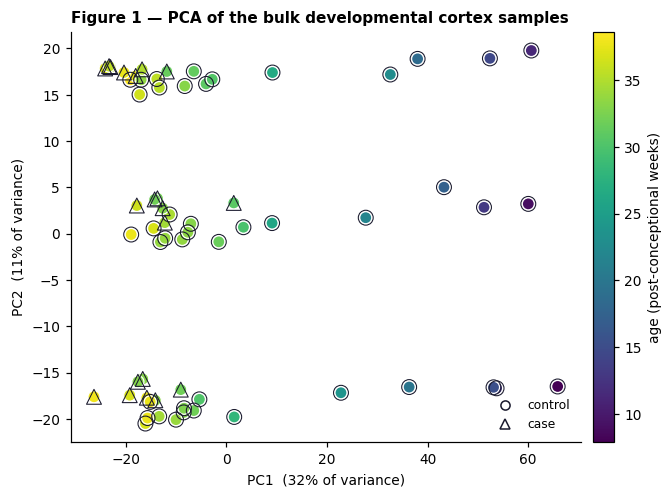

In [5]:
b, de, var_ratio = cc.block_a(bulk)        # normalise → log1p → HVG → PCA, then the case/control test
print("variance explained by the first five PCs:",
      np.round(var_ratio[:5] * 100, 1), "%")

fig, ax = plt.subplots(figsize=(6.4, 4.6))
figure1(b, ax); fig.tight_layout()
fig.savefig("figures/figure1.png", dpi=200)
plt.show()

> **Worksheet Q1a.** Which variable best explains the separation along PC1? Justify it *from the plot*.
>
> Before you answer, colour the same plot by something else. The cell below does that — change
> `"batch"` to `"region"`, `"sex"`, `"RIN"` or `"PMI_h"` and look again. **Q1b** asks which covariate
> you would check before trusting any differential expression result, and what you would conclude if
> cases and controls separated on it.

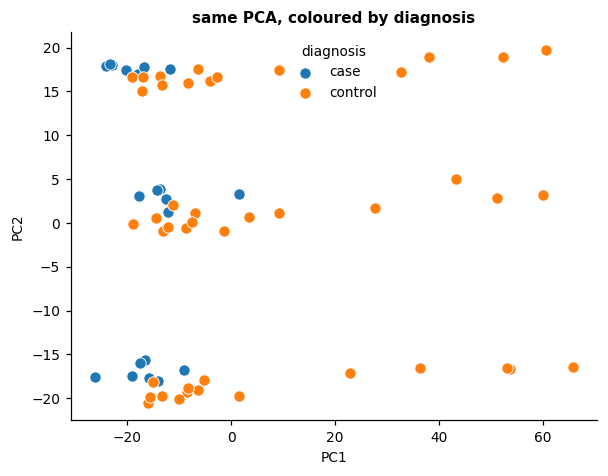

In [12]:
COLOUR_BY = "diagnosis"          # <-- try: batch, region, sex, RIN, PMI_h, diagnosis

pcs = b.obsm["X_pca"]
v = b.obs[COLOUR_BY]
fig, ax = plt.subplots(figsize=(5.6, 4.4))
if v.dtype.kind in "fi":
    sm = ax.scatter(pcs[:, 0], pcs[:, 1], c=v, cmap="magma", s=55, edgecolor="w", lw=0.6)
    plt.colorbar(sm, ax=ax, label=COLOUR_BY)
else:
    for lev in sorted(v.unique()):
        k = (v == lev).values
        ax.scatter(pcs[k, 0], pcs[k, 1], s=55, edgecolor="w", lw=0.6, label=str(lev))
    ax.legend(frameon=False, title=COLOUR_BY)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("same PCA, coloured by " + COLOUR_BY)
fig.tight_layout()
plt.show()

### A2 · Differential expression — **Figure 2**

The contrast is cases vs controls, restricted to the 40 age-matched samples. Two things decide whether
a gene is on the plot: the **effect size** (log₂ fold change, x-axis) and the **evidence** (p-value,
y-axis, corrected for testing ~2700 genes at once with Benjamini–Hochberg).

`|log₂FC| > 0.58` is a 1.5-fold change. Neither axis alone is enough: a tiny change can be highly
significant with a large n, and a huge fold change in a barely-expressed gene means nothing.

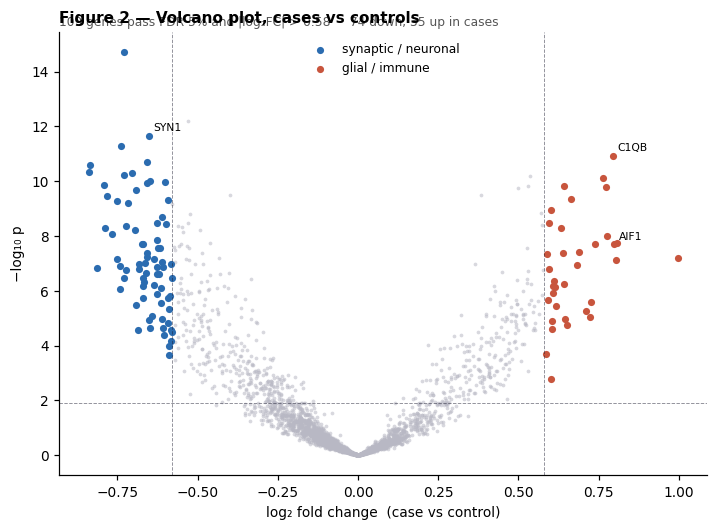

109 genes pass:  74 down and 35 up in cases


In [13]:
from cc_datasets import SYNAPTIC_MODULE, IMMUNE_MODULE

fig, ax = plt.subplots(figsize=(6.6, 4.9))
_, n_sig = figure2(de, SYNAPTIC_MODULE, IMMUNE_MODULE, ax)
fig.tight_layout(); fig.savefig("figures/figure2.png", dpi=200)
plt.show()

sig = de[(de.padj < 0.05) & (de.log2FC.abs() > 0.58)]
print(f"{len(sig)} genes pass:  {int((sig.log2FC < 0).sum())} down and "
      f"{int((sig.log2FC > 0).sum())} up in cases")

In [18]:
# The named genes on each side. This is the table Q2a wants you to read.
named = [g for g in sig.index if not g.startswith(("GENE", "AC0"))]
display(sig.loc[named].sort_values("log2FC").head(15).round(3))
display(sig.loc[named].sort_values("log2FC", ascending=False).head(15).round(3))
print("SYN1:", de.loc["SYN1"].round(4).to_dict())
import numpy as np

syn1 = b.raw[:, "SYN1"].X
syn1 = syn1.toarray().ravel() if hasattr(syn1, "toarray") else np.asarray(syn1).ravel()

print("Mean SYN1 expression:", syn1.mean())
print("Median SYN1 expression:", np.median(syn1))
print("SYN1 expression range:", syn1.min(), syn1.max())
import pandas as pd

pd.DataFrame({
    "diagnosis": b.obs["diagnosis"].to_numpy(),
    "SYN1": syn1
}).groupby("diagnosis")["SYN1"].agg(["mean", "median"])


,log2FC,pval,padj
gene,,,
CAMK2A,-0.839,0.0,0.000
NRXN3,-0.812,0.0,0.000
CAMK2B,-0.750,0.0,0.000
DLG4,-0.684,0.0,0.000
STX1A,-0.682,0.0,0.000
SYP,-0.670,0.0,0.000
SYN1,-0.651,0.0,0.000
TUBB3,-0.618,0.0,0.000
BSN,-0.592,0.0,0.000


,log2FC,pval,padj
gene,,,
CD74,0.806,0.0,0.0
TYROBP,0.804,0.0,0.0
AIF1,0.798,0.0,0.0
C1QB,0.795,0.0,0.0
TREM2,0.775,0.0,0.0
C1QA,0.773,0.0,0.0
C1QC,0.765,0.0,0.0
ITGAM,0.740,0.0,0.0
CX3CR1,0.722,0.0,0.0


SYN1: {'log2FC': -0.6513, 'pval': 0.0, 'padj': 0.0}
Mean SYN1 expression: 10.073745
Median SYN1 expression: 10.067787
SYN1 expression range: 9.493764 10.656593


,mean,median
diagnosis,,
case,9.853666,9.855158
control,10.173781,10.234623


> **Worksheet Q2a.** Roughly how many genes pass, and which functional category dominates each side?
>
> **Worksheet Q2b.** A reviewer objects that a log₂FC of −0.4 on *SYN1* is too small to matter.
> Give one argument for the reviewer and one against. Look at how highly *SYN1* is expressed
> (`b.raw[:, "SYN1"]`) before you decide, and at how many other genes move in the same direction.

---
# Block B — single-cell  ·  25 minutes

`fetal_cortex_sc.h5ad` is 8,000 nuclei from mid-gestation human cortex, **raw counts with no QC
applied**. Every barcode in this file is a droplet, and a droplet is not the same thing as a cell:
some are empty and contain only ambient RNA, some contain two cells, and some contain a cell that
was already damaged when it went in.

Deciding which barcodes to keep is the first real analytical decision of the day, and it is a
*biological* decision, not a threshold you copy from a tutorial.

In [19]:
sc_data = sc.read_h5ad("data/fetal_cortex_sc.h5ad")
print(sc_data)
print("\nsparsity: {:.1%} of the matrix is zero".format(
    1 - sc_data.X.nnz / (sc_data.n_obs * sc_data.n_vars)))

AnnData object with n_obs × n_vars = 8000 × 2747
    obs: 'donor', 'chemistry'
    var: 'mt'
    uns: 'about'
    layers: None (.X)

sparsity: 67.2% of the matrix is zero


### B1 · QC as a decision — **Figure 3**

Three metrics per barcode: total UMI counts, number of genes detected, and the percentage of counts
coming from mitochondrial transcripts.

Instead of fixed cut-offs, flag barcodes that are more than *k* **MADs** (median absolute deviations)
from the median of *this* sample. A MAD is a median-based standard deviation: it is not dragged around
by the outliers you are trying to find, and it adapts to each dataset.

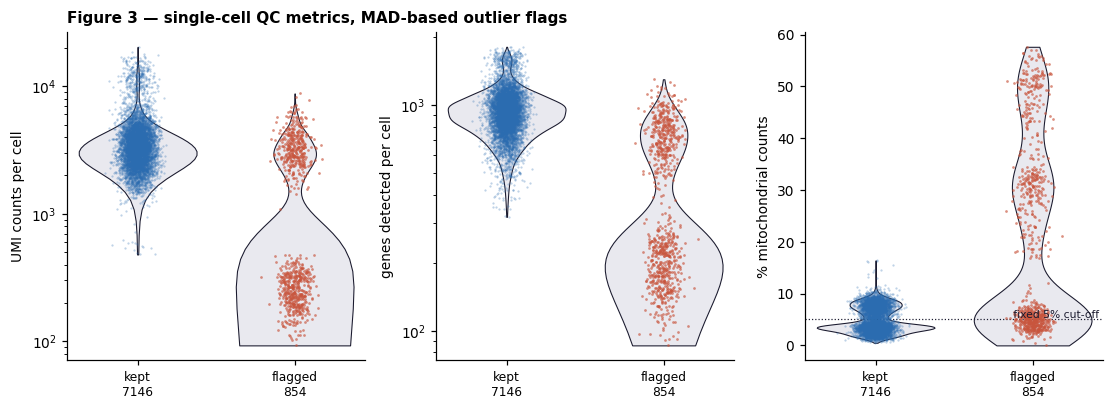

out_counts    465
out_genes     455
out_mt        389
qc_fail       854
dtype: int64

854 of 8000 barcodes flagged (10.7%)
median %MT: 4.11
a blanket 5% MT cut-off would remove: 3360 barcodes


In [21]:
N_MAD = 5        # <-- try 3 and 5 and watch how many cells you lose
MT_MAD = 5

s = cc.block_b_qc(sc_data.copy(), n_mad=N_MAD, mt_mad=MT_MAD)

fig, axes = plt.subplots(1, 3, figsize=(10.2, 3.8))
figure3(s, axes); fig.tight_layout(); fig.savefig("figures/figure3.png", dpi=200)
plt.show()

print(s.obs[["out_counts", "out_genes", "out_mt", "qc_fail"]].sum())
print(f"\n{int(s.obs.qc_fail.sum())} of {s.n_obs} barcodes flagged "
      f"({s.obs.qc_fail.mean():.1%})")
print("median %MT:", round(float(np.median(s.obs.pct_counts_mt)), 2))
print("a blanket 5% MT cut-off would remove:", int((s.obs.pct_counts_mt > 5).sum()), "barcodes")

> **Worksheet Q3a.** Which cells would you remove, on which metric, at what threshold — and *how did
> you choose it*? "Because the tutorial said so" is worth half marks.
>
> **Worksheet Q3b.** Compare the two numbers the cell above printed. Which population are you deleting
> with a blanket 5% mitochondrial cut-off in fetal cortex, and why is that population MT-rich?

### B2 · Embed, cluster, annotate

The standard route: normalise → log → pick highly variable genes → PCA → neighbour graph → Leiden
→ UMAP. This takes about a minute.

The UMAP is a *picture of the neighbour graph*, nothing more. Distance between clusters on it is not
meaningful, and a cluster is a hypothesis, not a cell type.

In [22]:
RESOLUTION = 0.6      # <-- higher splits more; the number of clusters is your choice, not a fact

s = cc.block_b_cluster(s, resolution=RESOLUTION)
print(s.obs.cluster.value_counts().sort_index())

/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


cluster
A    1183
B    1040
C     919
D     808
E     752
F     472
G     400
H     385
I     352
J     224
K     212
L     179
M      40
N      37
O      36
P      18
Q      16
R      15
S      13
T      13
U      12
V      10
W      10
Name: count, dtype: int64


### B3 · Markers make it a cell type — **Figure 4**

The dot plot: one row per cluster, one column per marker gene. **Dot size** = the fraction of cells in
that cluster expressing the gene; **colour** = the mean expression, scaled across clusters.

A good call needs a marker that is *specific*. `SLC1A3` alone will not separate radial glia from
astrocytes — both express it.

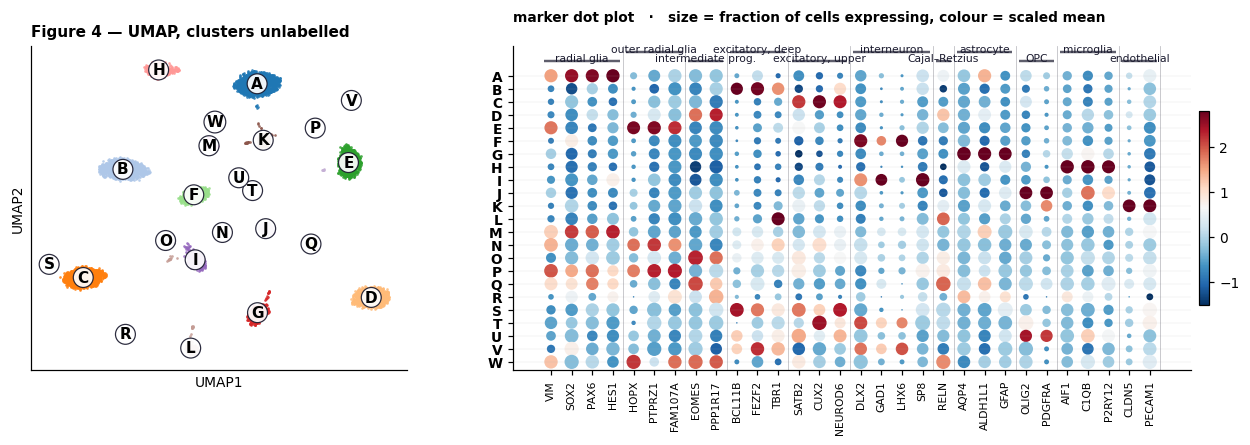

In [23]:
fig = figure4(s)
fig.subplots_adjust(left=0.04, right=0.97, top=0.88, bottom=0.24)
fig.savefig("figures/figure4.png", dpi=200)
plt.show()

In [24]:
# The unbiased version: what are the top-ranked genes of each cluster, marker panel or not?
sc.tl.rank_genes_groups(s, "cluster", method="wilcoxon")
pd.DataFrame(s.uns["rank_genes_groups"]["names"]).head(8)

,A,B,C,D,E,F,G,H,I,J,...,N,O,P,Q,R,S,T,U,V,W
0,HES5,SOX5,RORB,ELAVL4,HOPX,AC001728.1,GENE01723,C1QC,NR2F2,GENE00635,...,GENE01880,EOMES,AC001866.1,AC002271.1,C1QA,GENE01088,GENE02489,AC001065.1,GENE00869,AC002022.1
1,GENE00491,FEZF2,GENE01504,GENE02336,LIFR,CACNA1E,GENE01129,GENE00797,GENE00925,GENE02053,...,AC000498.1,NEUROG2,GENE01685,AC000459.1,SST,GENE01943,AC001056.1,AC001116.1,GENE02443,AC001866.1
2,GENE00629,CRYM,CAMK2B,NEUROG2,GENE02480,AC001686.1,AC001476.1,AIF1,AC000972.1,GENE02017,...,GENE01619,AC001302.1,GENE00533,PENK,PPP1R17,GENE01819,GENE01664,GENE01913,AC001728.1,GENE00218
3,AC000405.1,AC001215.1,AC002334.1,GENE00350,GENE01127,SYN2,CLU,C1QB,GRIN1,CCL4,...,GENE00565,GENE00056,GENE01603,GENE01451,AC001935.1,GENE01676,AC002058.1,AC001392.1,SOX5,GENE01469
4,AC002214.1,CAMK2A,CUX2,AC001959.1,GENE02077,GENE00110,GENE01553,CSF1R,GENE00250,GENE00184,...,AC001437.1,AC001062.1,GENE01127,GENE00796,FAM107A,AC000105.1,AC001545.1,GENE00622,GENE00110,GENE00821
5,GENE00722,NRXN1,GENE02278,AC001062.1,SLC1A3,CPLX2,AC001572.1,AC001500.1,GENE02156,GENE01324,...,AC001944.1,GENE00070,AC000354.1,EOMES,SOX5,GENE02278,AC002430.1,GENE01405,GABRB3,AC000435.1
6,GENE01289,GENE01135,POU3F2,GENE01187,AC000786.1,GENE02428,GENE02048,IFITM3,SP8,GENE01660,...,AC001845.1,AC002481.1,GENE01720,AC001227.1,GENE02536,GENE01318,AC000678.1,GENE00898,SST,AC000942.1
7,HES1,GENE00830,AC002454.1,AC000942.1,AC001839.1,GENE00908,GENE01412,AC001509.1,AC000312.1,GENE00833,...,GENE02480,GENE00350,AC001797.1,GENE00815,AQP4,SHANK3,GENE00848,GENE01190,GENE01799,GENE01456


> **Worksheet Q4a.** Give clusters **A**, **B** and **C** a cell-type identity, and name the marker
> gene(s) you used for each. Identity without a marker scores half.
>
> **Worksheet Q4b.** One of the three is ambiguous. Say which, and name one extra gene or one analysis
> that would settle it. The `rank_genes_groups` table above is a good place to look.

Fill in your calls below — Block C uses them.

In [29]:
# Your annotation. Leave a cluster as its letter if you are not sure.
MY_LABELS = {
    "A": "Radial glia",
    "B": "Excitatory neurons - deep layer",
    "C": "Excitatory neurons - upper layer",
}

for c in s.obs.cluster.cat.categories:
    MY_LABELS.setdefault(c, c)

MY_LABELS

{'A': 'Radial glia',
 'B': 'Excitatory neurons - deep layer',
 'C': 'Excitatory neurons - upper layer',
 'D': 'D',
 'E': 'E',
 'F': 'F',
 'G': 'G',
 'H': 'H',
 'I': 'I',
 'J': 'J',
 'K': 'K',
 'L': 'L',
 'M': 'M',
 'N': 'N',
 'O': 'O',
 'P': 'P',
 'Q': 'Q',
 'R': 'R',
 'S': 'S',
 'T': 'T',
 'U': 'U',
 'V': 'V',
 'W': 'W'}

---
# Block C — spatial and integration  ·  20 minutes

This is where the three technologies stop being three separate exercises.

### C1 · Deconvolve the Block A bulk with your Block B annotation — **Figure 5**

A bulk sample is a mixture. Written out:

$$ y_g \;=\; \sum_k p_k \, e_{g,k} $$

the bulk expression of gene *g* is the sum, over cell types *k*, of that type's proportion $p_k$ times
what one cell of that type transcribes, $e_{g,k}$. Your single-cell object gives you $e$. Solving for
$p$ is **deconvolution** — here, a non-negative least squares fit of each bulk sample against the
cluster signature.

Then look again at Figure 2. If $y_g$ changed, either $p$ changed, or $e$ changed, or both.

signature: 446 genes × 13 clusters


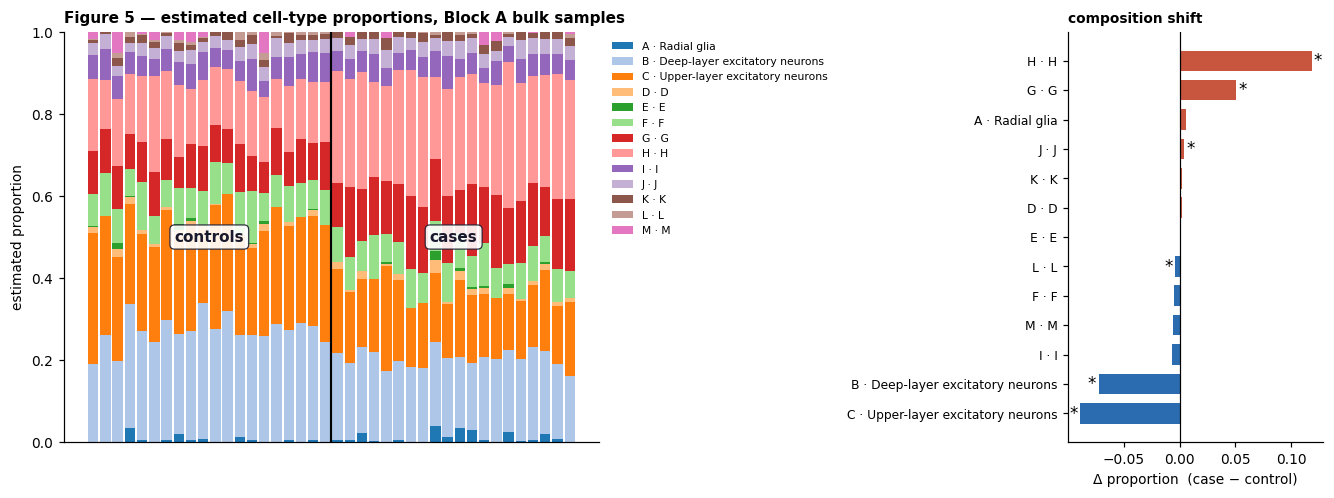

,type,delta,p
2,C · Upper-layer excitatory neurons,-0.0893,0.0000
1,B · Deep-layer excitatory neurons,-0.0725,0.0000
8,I · I,-0.0064,0.0720
12,M · M,-0.0057,0.2832
5,F · F,-0.0050,0.5979
11,L · L,-0.0044,0.0023
4,E · E,0.0001,0.9424
3,D · D,0.0022,0.4395
10,K · K,0.0025,0.1895
9,J · J,0.0042,0.0155


In [27]:
signature = cc.signature_matrix(s)             # linear-scale mean expression per cluster
print("signature:", signature.shape[0], "genes ×", signature.shape[1], "clusters")

# bulk on the same linear CPM scale the equation is written on
Cb = cc._dense(bulk[:, b.var_names]); Cb = Cb / Cb.sum(1, keepdims=True) * 1e4
bulk_cpm = pd.DataFrame(Cb, index=b.obs_names, columns=b.var_names)

props = cc.deconvolve(bulk_cpm, signature)
labels = {c: f"{c} · {MY_LABELS.get(c, c)}" for c in props.columns}

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.6), gridspec_kw={"width_ratios": [2.1, 1]})
_, comp = figure5(props, b.obs, labels, axes)
fig.tight_layout(); fig.savefig("figures/figure5.png", dpi=200)
plt.show()
comp.round(4)

Now the analysis that actually answers the question. Re-run the case/control test with the estimated
neuronal fraction as a covariate, and plot each gene's effect size before against after.

A gene that stays on the diagonal is one that composition does not explain. A gene pulled towards zero
is one whose apparent regulation was, at least partly, a change in how many neurons were in the tube.

treating these as neuronal: ['B', 'C']


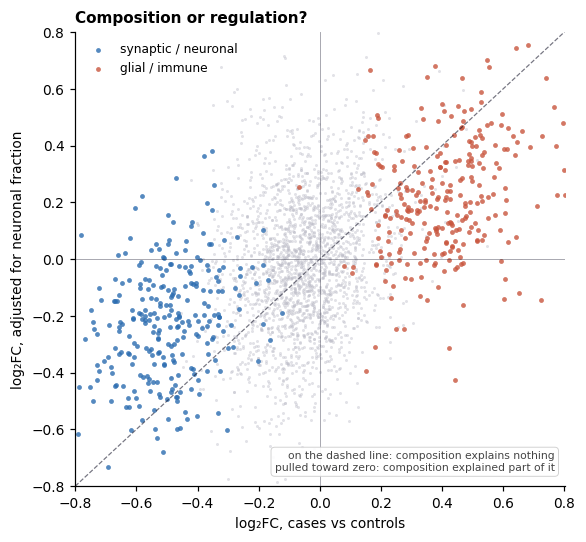


synaptic module, down in cases:
  significant before adjusting: 262
  significant after  adjusting: 31
  median shrinkage of the effect: 51%


In [30]:
# Which of your clusters are neurons? Taken from your MY_LABELS if you filled it in;
# otherwise scored automatically from SNAP25 / NEUROD6 / GAD1 and friends.
NEURONAL = [c for c in props.columns
            if MY_LABELS.get(c, "").lower().startswith(("exn", "in_", "cr", "excit", "inter", "neuro"))]
if not NEURONAL:
    NEURONAL = [c for c in cc.neuronal_clusters(s) if c in props.columns]
    print("(MY_LABELS not filled in — scoring neuronal clusters from markers instead)")
print("treating these as neuronal:", NEURONAL)

adj = cc.adjusted_de(b, props, NEURONAL)
fig, ax = plt.subplots(figsize=(5.4, 5.0))
figure5b(adj, SYNAPTIC_MODULE, IMMUNE_MODULE, ax)
fig.tight_layout(); fig.savefig("figures/figure5b.png", dpi=200)
plt.show()

syn = adj.index.isin(SYNAPTIC_MODULE)
print("\nsynaptic module, down in cases:")
print("  significant before adjusting:",
      int(((adj.pval_crude < 0.05) & (adj.log2FC_crude < 0) & syn).sum()))
print("  significant after  adjusting:",
      int(((adj.pval_adj < 0.05) & (adj.log2FC_adj < 0) & syn).sum()))
print("  median shrinkage of the effect: {:.0%}".format(adj.shrinkage[syn].median()))

> **Worksheet Q5a — the keystone question.** Using the proportions in Figure 5, re-explain the
> differential expression result you described in Q2a. Composition, regulation, or both? Say what
> evidence you are using — the numbers the cell above printed are evidence.
>
> **Worksheet Q5b.** Name one limitation of *your* deconvolution that could make that conclusion
> wrong. Compare the microglial proportion you estimated to what you would expect in fetal cortex,
> and think about where the reference came from.

### C2 · Where in the tissue? — **Figure 6** and **Figure 6b**

Unlike the bulk and single-cell data, the Visium data is **real**. It comes from coronal sections of rat
brain hemispheres, taken **5 and 40 days after a status epilepticus (SE)** or from control animals. You get four sections,
mounted as two pairs on two slides, so each control is on the same slide as its SE section:

| Section | Condition | Days after SE | Slide |
|---|---|---|---|
| `B_L1_S2` | control | 5 | L1 |
| `A_L1_S1` | SE | 5 | L1 |
| `D_L2_S8` | control | 40 | L2 |
| `C_L2_S7` | SE | 40 | L2 |

Each spot is 55 µm across, the spots are 100 µm apart, and each one gives a whole transcriptome plus
an (x, y) position on the H&E image. Clustering the spots of all 16 sections of the full experiment
found the **spatial domains** numbered 1 to 8. The numbers are shuffled: nothing tells you which domain
is which.

The six-layered neocortex in these sections is what the fetal cortical wall of Blocks A and B turns
into. Deep layers were born first and upper layers last (*inside-out*), and the position of a neuron
still tells you its identity.

In [31]:
if not HAVE_VISIUM:
    raise SystemExit("No Visium data in this runtime: use Figures 6 and 6b of the handout.")

visium = sc.read_h5ad("data/rat_visium_SE.h5ad")
print(visium)
v = cc.visium_normalise(visium)        # raw counts kept in v.layers["counts"]; log1p(counts per 10k) in v.X
v.obs.groupby(["section", "condition", "days_post_SE", "slide"], observed=True).size()

AnnData object with n_obs × n_vars = 13242 × 5009
    obs: 'section', 'condition', 'days_post_SE', 'slide', 'domain', 'total_counts', 'n_genes', 'array_row', 'array_col'
    uns: 'about', 'spatial'
    obsm: 'spatial'
    layers: None (.X)


section  condition  days_post_SE  slide
A_L1_S1  SE         5             L1       3465
B_L1_S2  control    5             L1       3399
C_L2_S7  SE         40            L2       2900
D_L2_S8  control    40            L2       3478
dtype: int64

**QC in space first.** Look at the total counts per spot on the tissue, not only as a distribution.
Compare the four sections with each other: whatever differs between them before any biology is
what normalisation has to absorb.

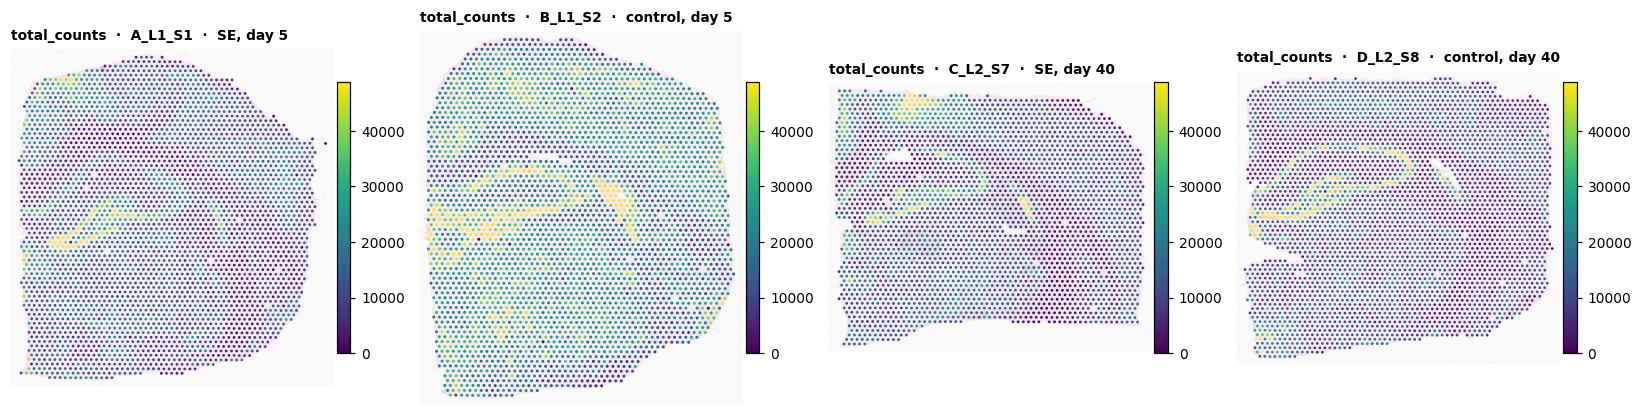

section
A_L1_S1    14280.0
B_L1_S2    25903.0
C_L2_S7    12500.0
D_L2_S8    11805.0
Name: total_counts, dtype: float64

In [32]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
vmax = np.percentile(v.obs.total_counts, 99)
for ax, s in zip(axes, v.obs.section.cat.categories):
    cc.plot_spots(ax, v, s, "total_counts", vmax=vmax, cmap="viridis")
fig.tight_layout()
plt.show()
v.obs.groupby("section", observed=True).total_counts.median()

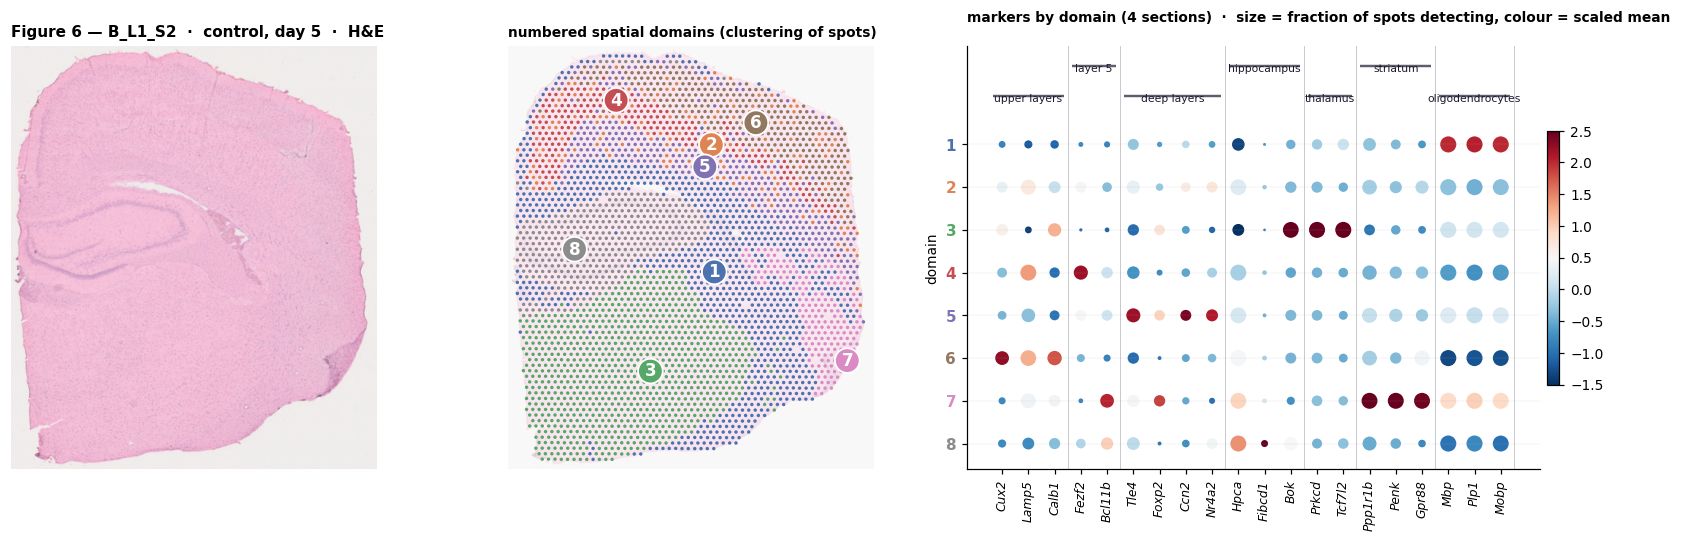

In [33]:
SECTION = "B_L1_S2"      # <-- any of the four sections; the domain numbers are the same in all four

fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.0), gridspec_kw={"width_ratios": [1, 1, 1.55]})
figure6(v, SECTION, axes)
fig.tight_layout(); fig.savefig("figures/figure6.png", dpi=200)
plt.show()

Some domains are bands that follow the surface of the brain. To find which side is the pial surface
and which side faces the white matter, look at one gene at a time on the tissue. Try `Cux2`, `Fezf2`,
`Tle4`, `Ccn2`, `Mbp`.

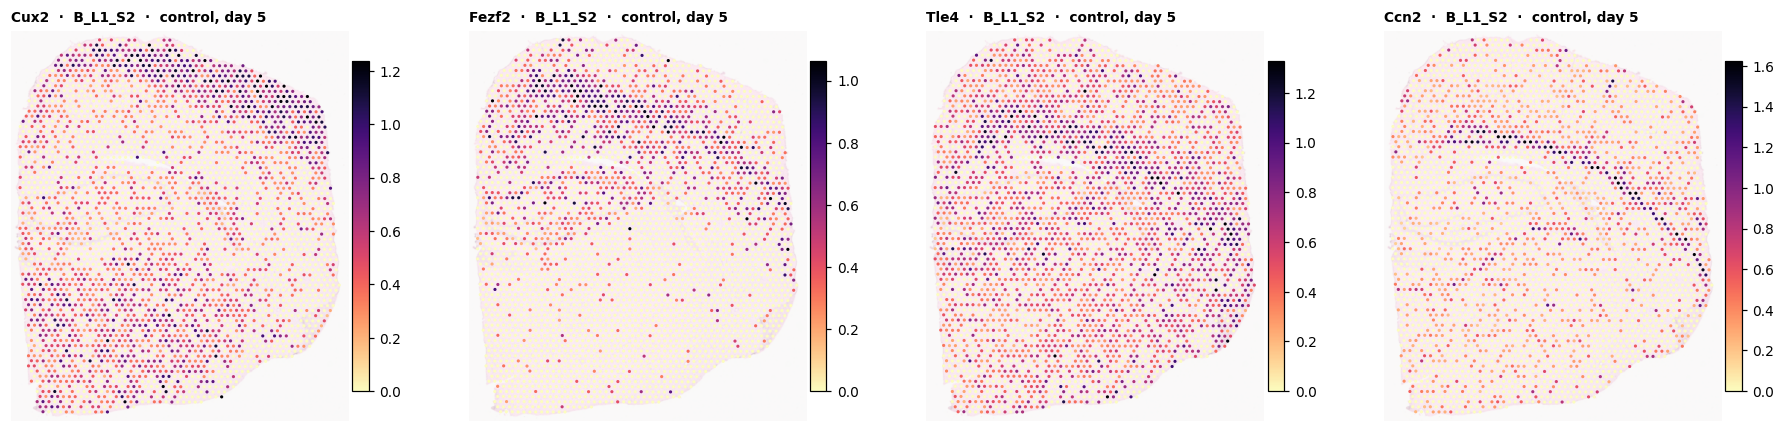

In [34]:
GENES = ["Cux2", "Fezf2", "Tle4", "Ccn2"]      # <-- any gene in v.var_names

fig, axes = plt.subplots(1, len(GENES), figsize=(4.2 * len(GENES), 4.0))
for ax, g in zip(np.atleast_1d(axes), GENES):
    cc.plot_spots(ax, v, SECTION, g)
fig.tight_layout()
plt.show()

> **Worksheet Q6a.** Which numbered domains are **neocortex**? Order them from the **pial surface** to
> the **white matter** and name the layer(s) each one corresponds to, citing one marker gene for each.
> Say how you decided which side of the section is the pial surface.

#### SE versus control

Now the same tissue after a status epilepticus. Figure 6b shows *Gfap*, the classic marker of reactive
astrocytes, on the four sections with one shared colour scale. Below it, every domain is summed into one
**pseudobulk** profile and compared between SE and control, for a reactive gene (*Gfap*, *Vim*), stable
astrocyte markers (*Aqp4*, *Slc1a3*), microglial markers (*Aif1*, *Cd68*) and neuronal genes
(*Hpca*, *Camk2a*, *Snap25*).

A spot is a miniature bulk sample, so the bulk equation of C1 applies to it as well.

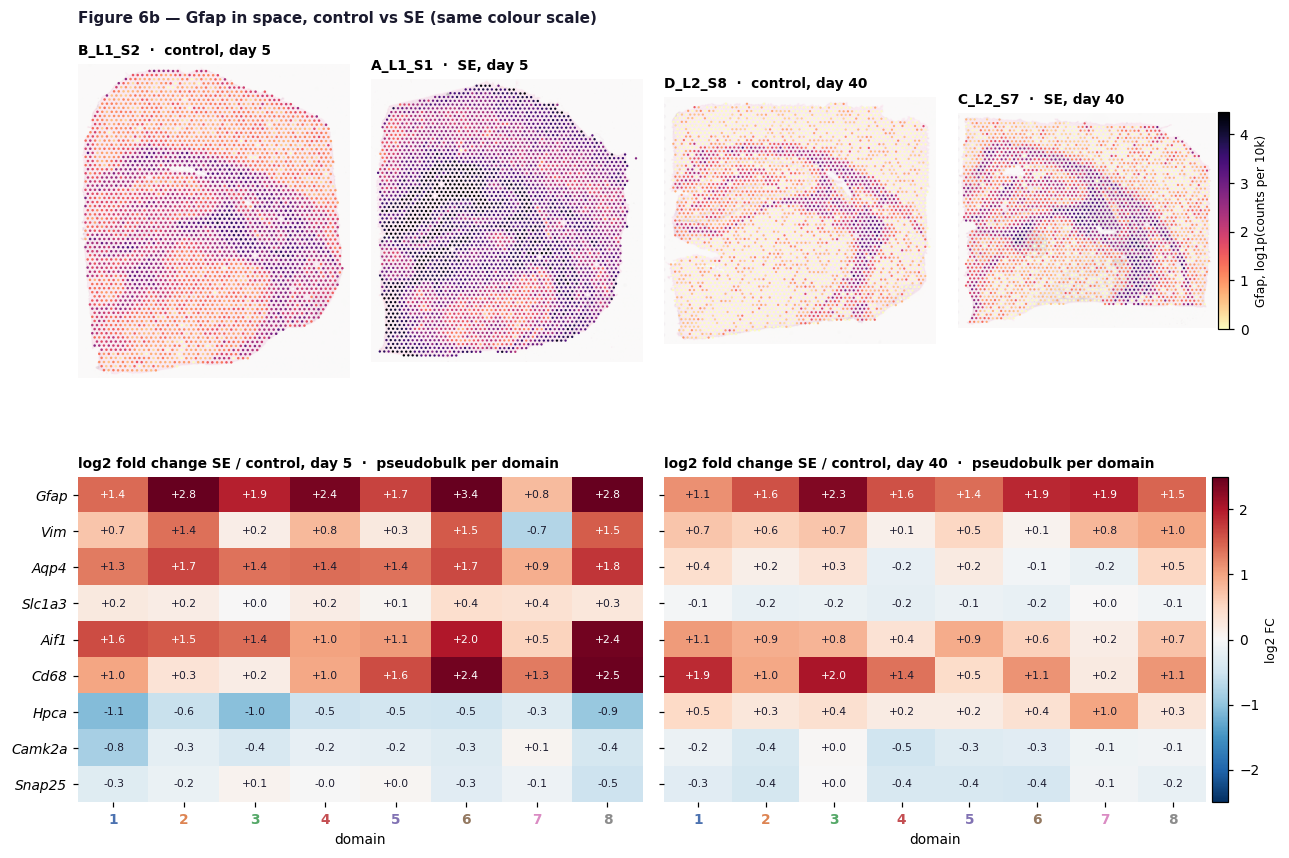

In [35]:
GENE = "Gfap"      # <-- try Aif1, Cd68, Vim, Hpca

fig = figure6b(v, GENE)
fig.savefig("figures/figure6b.png", dpi=200, bbox_inches="tight")
plt.show()

In [36]:
# The numbers behind the heat maps: log2 fold change SE / control, one column per domain.
print("day 5");  display(cc.pseudobulk_log2fc(v, cc.GLIOSIS_PANEL, 5).round(2))
print("day 40"); display(cc.pseudobulk_log2fc(v, cc.GLIOSIS_PANEL, 40).round(2))

day 5


,1,2,3,4,5,6,7,8
Gfap,1.41,2.75,1.94,2.37,1.70,3.42,0.80,2.75
Vim,0.69,1.38,0.16,0.80,0.25,1.53,-0.74,1.51
Aqp4,1.29,1.66,1.36,1.40,1.35,1.66,0.91,1.78
Slc1a3,0.24,0.19,0.01,0.19,0.07,0.42,0.39,0.29
Aif1,1.63,1.54,1.39,1.01,1.07,2.01,0.55,2.42
Cd68,0.99,0.34,0.19,0.96,1.63,2.42,1.29,2.46
Hpca,-1.08,-0.55,-1.04,-0.53,-0.45,-0.50,-0.32,-0.94
Camk2a,-0.83,-0.25,-0.40,-0.20,-0.23,-0.33,0.07,-0.43
Snap25,-0.31,-0.16,0.08,-0.01,0.05,-0.29,-0.14,-0.52


day 40


,1,2,3,4,5,6,7,8
Gfap,1.15,1.59,2.31,1.60,1.41,1.88,1.94,1.46
Vim,0.70,0.57,0.69,0.13,0.51,0.09,0.83,0.97
Aqp4,0.42,0.15,0.33,-0.21,0.23,-0.07,-0.17,0.51
Slc1a3,-0.05,-0.18,-0.16,-0.23,-0.15,-0.19,0.01,-0.08
Aif1,1.07,0.91,0.84,0.35,0.93,0.58,0.18,0.72
Cd68,1.87,0.97,2.05,1.36,0.45,1.13,0.22,1.10
Hpca,0.50,0.28,0.40,0.20,0.20,0.39,0.98,0.30
Camk2a,-0.15,-0.39,0.04,-0.51,-0.33,-0.29,-0.11,-0.08
Snap25,-0.28,-0.44,0.01,-0.40,-0.41,-0.41,-0.08,-0.18


> **Worksheet Q6b.** *Gfap* is strongly up in the SE section at day 5. From the spots alone, can you tell
> whether there are **more astrocytes** or whether each astrocyte makes **more *Gfap***? Use the other
> genes in Figure 6b as evidence, keep in mind that one spot holds several cells, and name one experiment
> or analysis that would settle the question.

### C3 · Q7 — no code

> You want to test whether **outer radial glia are reduced in a cortical malformation**. You have 40
> frozen post-mortem samples (20 cases, 20 controls), and budget for bulk RNA-seq on all 40 plus
> **one** of the other two technologies on about 8 samples.
>
> In 4–6 sentences: what would you run on what, in which order, and what is your primary readout?
> Then name one question your design cannot answer.

Two things you have seen today are worth remembering while you write. Deconvolution needs a reference
built first, from the same stage and region. And the frozen tissue rules out one of the three assays
in the form you used it here.

---
### Before you hand in

All the figures are saved in `figures/`. Check that the numbers in your answers match your own output,
not the lecture slides.

In [ ]:
import glob
for f in sorted(glob.glob("figures/*.png")):
    print(f, round(os.path.getsize(f) / 1e3), "kB")

if IN_COLAB:
    from google.colab import files
    # uncomment to download all the figures as a zip
    # !zip -qr figures.zip figures && files.download("figures.zip")